# Entrega 5 — Obtenção, limpeza e tratamento dos dados de exportação da Paraíba

**TPAE II (PSAE00320) · Projeto aplicado de extensão · Turma 01 · 2026.2 · Equipe 03**
Demandante: Corecon-PB · Projeto: *Planejamento de Exportação para PMEs na Paraíba*

---

## 1. Objetivo, fontes e produtos gerados

**Objetivo.** Importar, inspecionar, limpar, relacionar, transformar e validar duas bases do Comex Stat (MDIC) sobre as exportações dos municípios paraibanos, produzindo uma **base analítica integrada** — sem editar os dados originais e registrando cada transformação.

**Fontes (somente leitura, em `dados/brutos/`)**

| Base | Arquivo | Unidade de detalhamento | Período | Variáveis |
|---|---|---|---|---|
| 1 | `H_EXPORTACAO_POR_MUNICIPIO_2021-01_2025-12_DT20261022.xlsx` | **município × produto (SH4)** | 2021–2025 (anual, formato largo) | Valor US$ FOB e Quilograma Líquido por ano |
| 2 | `H_EXPORTACAO_POR_MUNICIPIO_2026-01_2026-12_DT20261022.xlsx` | **município × país de destino** | 2026 (consulta Jan–Dez, **extraída em 22/10/2026**) | Valor US$ FOB e Quilograma Líquido |

Cada arquivo tem a aba `Resultado` (dados) e a aba `Detalhamento` (parâmetros da consulta original) — esta última é lida, preservada e registrada em `registro_fontes.csv`.

**Problema estrutural central.** As bases têm **granularidades diferentes** (produto × país) e só compartilham o município. Uma junção direta por município geraria um produto cartesiano (cada produto "exportado" para cada país) e **multiplicaria os valores**. Por isso o desenho adotado mantém **três tabelas** (uma por tipo de unidade observacional) e liga as bases apenas **após agregar ao nível do município**:

| # | Produto gerado | Grão (1 linha =) |
|---|---|---|
| 1 | `exportacoes_municipio_produto_2021_2025.csv` | município × produto SH4 × ano |
| 2 | `exportacoes_municipio_pais_2026.csv` | município × país de destino (2026) |
| 3 | `exportacoes_municipio_consolidado.csv` | município (indicadores agregados das duas bases) |
| + | `exportacoes_municipio_ano.csv` | município × ano (2021–2026; versão tidy dos totais) |
| + | `dicionario_dados.csv`, `registro_fontes.csv`, `log_transformacoes.csv`, `testes_validacao.csv` | documentação |
| + | `relatorio/relatorio_qualidade_dados.md/.csv/.pdf` | relatório de qualidade |

**Estrutura do notebook:** 1 Configuração · 2 Importação · 3 Diagnóstico e limpeza · 4 Relacionamento entre as bases · 5 Transformação · 6 Validação · 7 Exportação e resumo das decisões.

**Como executar.** *Kernel → Reiniciar e executar tudo.* O notebook localiza a raiz do projeto (a pasta que contém `dados/brutos/`) a partir do diretório atual ou da variável de ambiente `TPAE_RAIZ`; se os `.xlsx` não existirem, baixa-os do repositório do GitHub (ver `URL_RAW`). Nenhuma etapa depende de edição manual.

## Etapa 1 — Apresentação e configuração reproduzível

In [ ]:
# ------------------------------------------------------------------
# 1.1 Bibliotecas
# ------------------------------------------------------------------
import os, re, sys, json, hashlib, unicodedata, urllib.request, difflib
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import openpyxl
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

SEED = 42
np.random.seed(SEED)   # o pipeline é determinístico (não há etapa aleatória); fixado por precaução

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4


In [ ]:
# ------------------------------------------------------------------
# 1.2 Configuração de caminhos (todos configuráveis)
# ------------------------------------------------------------------
ARQ_A = "H_EXPORTACAO_POR_MUNICIPIO_2021-01_2025-12_DT20261022.xlsx"   # base 1: município x produto (2021-2025)
ARQ_B = "H_EXPORTACAO_POR_MUNICIPIO_2026-01_2026-12_DT20261022.xlsx"   # base 2: município x país (2026)

# Se os arquivos não estiverem em dados/brutos/, são baixados daqui (útil no Google Colab):
URL_RAW = "https://raw.githubusercontent.com/thiagopapel-econ/projeto-tpae-II/main/dados/brutos/"
BAIXAR_SE_AUSENTE = True

def localizar_raiz():
    """Raiz do projeto = pasta que contém dados/brutos. Pode ser forçada com a variável TPAE_RAIZ."""
    env = os.environ.get("TPAE_RAIZ")
    if env:
        return Path(env).expanduser().resolve()
    atual = Path.cwd().resolve()
    for p in [atual, *atual.parents]:
        if (p / "dados" / "brutos").is_dir():
            return p
    return atual   # fallback: pasta atual (as subpastas são criadas abaixo)

RAIZ            = localizar_raiz()
PASTA_BRUTOS    = RAIZ / "dados" / "brutos"      # ORIGINAIS: somente leitura (nunca escritos por este notebook)
PASTA_TRATADOS  = RAIZ / "dados" / "tratados"    # saídas processadas
PASTA_RELATORIO = RAIZ / "relatorio"
PASTA_FIGURAS   = PASTA_RELATORIO / "figuras"
for p in (PASTA_BRUTOS, PASTA_TRATADOS, PASTA_RELATORIO, PASTA_FIGURAS):
    p.mkdir(parents=True, exist_ok=True)

print("RAIZ           :", RAIZ)
print("Originais      :", PASTA_BRUTOS)
print("Processados    :", PASTA_TRATADOS)
print("Relatório      :", PASTA_RELATORIO)

RAIZ           : /home/claude/projeto-tpae-II
Originais      : /home/claude/projeto-tpae-II/dados/brutos
Processados    : /home/claude/projeto-tpae-II/dados/tratados
Relatório      : /home/claude/projeto-tpae-II/relatorio


In [ ]:
# ------------------------------------------------------------------
# 1.3 Infraestrutura de documentação: log de transformações e registro de testes
#     (tudo o que o notebook altera ou verifica fica registrado e é exportado na Etapa 7)
# ------------------------------------------------------------------
LOG = []      # log de transformações
TESTES = []   # resultados dos testes de integridade
ACHADOS = {}  # números do diagnóstico, reutilizados no relatório de qualidade

def registrar(etapa, base, operacao, antes, depois, justificativa):
    LOG.append({"ordem": len(LOG) + 1, "etapa": etapa, "base_tabela": base, "operacao": operacao,
                "antes": antes, "depois": depois, "justificativa": justificativa})

def testar(grupo, nome, condicao, esperado, obtido):
    TESTES.append({"grupo": grupo, "teste": nome, "esperado": str(esperado), "obtido": str(obtido),
                   "status": "OK" if bool(condicao) else "FALHA"})

# Formatadores pt-BR (só para textos do relatório)
def n(x):   return f"{int(round(x)):,}".replace(",", ".")
def usd(x): return "US$ " + n(x)
def pct(x, d=1): return f"{x:.{d}f}".replace(".", ",") + "%"

print("Infraestrutura pronta.")

Infraestrutura pronta.


## Etapa 2 — Importação dos dados

**Princípios:** (i) os arquivos em `dados/brutos/` são **apenas lidos**; (ii) a leitura é feita com `dtype=str` (sem inferência de tipos) e o resultado fica guardado em `raw_A`/`raw_B`, que **nunca são modificados** — todo tratamento ocorre em cópias; (iii) calculamos o **SHA-256** dos arquivos antes e depois para provar que os originais permaneceram intactos.

In [ ]:
# ------------------------------------------------------------------
# 2.1 Aquisição: localizar (ou baixar) os originais e registrar a impressão digital (SHA-256)
# ------------------------------------------------------------------
for nome in (ARQ_A, ARQ_B):
    destino = PASTA_BRUTOS / nome
    if not destino.exists():
        if not BAIXAR_SE_AUSENTE:
            raise FileNotFoundError(f"Arquivo ausente: {destino}")
        print(f"Baixando {nome} ...")
        urllib.request.urlretrieve(URL_RAW + nome, destino)

def sha256(caminho):
    h = hashlib.sha256()
    with open(caminho, "rb") as f:
        for bloco in iter(lambda: f.read(1 << 20), b""):
            h.update(bloco)
    return h.hexdigest()

ARQUIVOS = {"A": PASTA_BRUTOS / ARQ_A, "B": PASTA_BRUTOS / ARQ_B}   # A = base 1 (município x produto) | B = base 2 (município x país)
ROTULO = {"A": "1", "B": "2"}
HASH_INICIAL = {k: sha256(v) for k, v in ARQUIVOS.items()}
for k, v in ARQUIVOS.items():
    print(f"Base {ROTULO[k]}: {v.name} | {v.stat().st_size/1024:,.0f} KB | sha256 {HASH_INICIAL[k][:16]}...")

Base 1: H_EXPORTACAO_POR_MUNICIPIO_2021-01_2025-12_DT20261022.xlsx | 53 KB | sha256 04b3d1d54861831f...
Base 2: H_EXPORTACAO_POR_MUNICIPIO_2026-01_2026-12_DT20261022.xlsx | 9 KB | sha256 da9f259675908b7e...


In [ ]:
# ------------------------------------------------------------------
# 2.2 Leitura da aba "Resultado" (dtype=str: nenhum tipo é inferido pelo pandas)
# ------------------------------------------------------------------
raw_A = pd.read_excel(ARQUIVOS["A"], sheet_name="Resultado", dtype=str)
raw_B = pd.read_excel(ARQUIVOS["B"], sheet_name="Resultado", dtype=str)

# Assinatura dos DataFrames originais, para provar na Etapa 6 que não foram alterados
def assinatura(df):
    return int(pd.util.hash_pandas_object(df, index=True).sum())
ASSINATURA_RAW = {"A": assinatura(raw_A), "B": assinatura(raw_B)}

for nome, df in (("Base 1 (município x produto, 2021-2025)", raw_A), ("Base 2 (município x país, 2026)", raw_B)):
    print(f"\n=== {nome} ===  dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
    display(df.head(5))


=== Base 1 (município x produto, 2021-2025) ===  dimensões: 436 linhas x 14 colunas


,UF do Município,Município,Código SH4,Descrição SH4,2025 - Valor US$ FOB,2025 - Quilograma Líquido,2024 - Valor US$ FOB,2024 - Quilograma Líquido,2023 - Valor US$ FOB,2023 - Quilograma Líquido,2022 - Valor US$ FOB,2022 - Quilograma Líquido,2021 - Valor US$ FOB,2021 - Quilograma Líquido
0,Paraíba,Campina Grande - PB,6402,Outro calçado com sola exterior e parte superior de borracha ou pl...,52837919,5243338,39058696,4705490,58118889,5704267,64896551,6434005,50685439,7316979
1,Paraíba,Santa Rita - PB,1701,"Açúcares de cana ou de beterraba e sacarose quimicamente pura, no ...",36096278,78540200,32987247,56453033,40811309,71078173,4107486,8158690,5678516,14984787
2,Paraíba,Vieirópolis - PB,2516,"Granito, pórfiro, basalto, arenito e outras pedras de cantaria ou ...",7789948,1303102,4878646,1113495,2429935,533330,2061683,651326,3072461,1214033
3,Paraíba,Lucena - PB,2009,Sumos de frutas (incluídos os mostos de uvas) ou de produtos hortí...,7296901,4035998,3968398,2199236,4620550,2544455,4386632,2458532,4249645,2420985
4,Paraíba,Mamanguape - PB,0807,"Melões, melancias e papaias (mamões), frescos",6771934,4851121,4386543,3286036,5935814,3937246,4500982,3333202,4097174,3711705



=== Base 2 (município x país, 2026) ===  dimensões: 154 linhas x 5 colunas


,UF do Município,Município,País,2026 - Valor US$ FOB,2026 - Quilograma Líquido
0,Paraíba,Campina Grande - PB,Espanha,13403299,1832449
1,Paraíba,Campina Grande - PB,Filipinas,7904712,436465
2,Paraíba,Lucena - PB,Estados Unidos,6773188,3786058
3,Paraíba,Vieirópolis - PB,China,5709443,1163422
4,Paraíba,Campina Grande - PB,Austrália,5055916,294029


In [ ]:
# ------------------------------------------------------------------
# 2.3 Aba "Detalhamento": parâmetros das consultas originais (preservados na documentação das fontes)
# ------------------------------------------------------------------
def ler_detalhamento(caminho):
    d = pd.read_excel(caminho, sheet_name="Detalhamento", dtype=str, keep_default_na=False)
    return d

def resumir_detalhamento(d):
    p = d.iloc[0].to_dict()                                   # parâmetros escalares (linha 1)
    p["Detalhes"] = " | ".join(x for x in d["Detalhes"] if x.strip())   # dimensões da consulta
    p["Valores"]  = " | ".join(x for x in d["Valores"]  if x.strip())   # medidas da consulta
    return p

def data_da_consulta(nome_arquivo):
    m = re.search(r"DT(\d{8})", nome_arquivo)   # sufixo DTaaaammdd = data da extração
    return datetime.strptime(m.group(1), "%Y%m%d").date().isoformat() if m else None

DETALHAMENTO = {k: resumir_detalhamento(ler_detalhamento(v)) for k, v in ARQUIVOS.items()}
LINHAS_LIDAS = {"A": len(raw_A), "B": len(raw_B)}

registro_fontes = pd.DataFrame([
    {"base": {"A": "1", "B": "2"}[k],
     "arquivo": ARQUIVOS[k].name,
     "sha256": HASH_INICIAL[k],
     "tamanho_bytes": ARQUIVOS[k].stat().st_size,
     "data_extracao_dt_arquivo": data_da_consulta(ARQUIVOS[k].name),
     "fonte": "Comex Stat (MDIC) - exportação por município",
     "ano_inicial": d["Ano inicial"], "ano_final": d["Ano final"],
     "mes_inicial": d["Mês inicial"], "mes_final": d["Mês final"],
     "linhas_declaradas_detalhamento": int(d["Quantidade de linhas"]),
     "linhas_lidas_resultado": LINHAS_LIDAS[k],
     "tipo_exibicao": d["Tipo de exibição"], "tipo_consulta": d["Tipo de consulta"],
     "fluxo": d["Fluxo"], "tipo_ordenacao": d["Tipo de ordenação"],
     "filtro": d["Filtros"], "filtro_valor_codigo_uf": d["UF do Município"],
     "detalhes_(dimensoes)": d["Detalhes"], "valores_(medidas)": d["Valores"],
     "processado_em": datetime.now().isoformat(timespec="seconds"),
     "versao_pandas": pd.__version__}
    for k, d in DETALHAMENTO.items()])
display(registro_fontes.set_index("base").T)

base,1,2
arquivo,H_EXPORTACAO_POR_MUNICIPIO_2021-01_2025-12_DT20261022.xlsx,H_EXPORTACAO_POR_MUNICIPIO_2026-01_2026-12_DT20261022.xlsx
sha256,04b3d1d54861831f406fddbe7898e4119000df39f6532436e420974ec53a9f41,da9f259675908b7e68cafb6ff617a31450bc564e21741514d3a15c86776fa2cc
tamanho_bytes,54781,9547
data_extracao_dt_arquivo,2026-10-22,2026-10-22
fonte,Comex Stat (MDIC) - exportação por município,Comex Stat (MDIC) - exportação por município
ano_inicial,2021,2026
ano_final,2025,2026
mes_inicial,Janeiro,Janeiro
mes_final,Dezembro,Dezembro
linhas_declaradas_detalhamento,436,154


In [ ]:
# ------------------------------------------------------------------
# 2.4 Tipos de dados: o que está de fato gravado nas células do Excel?
#     Diagnóstico da coluna "Código SH4" (suspeita de tipo misto: inteiro x texto)
# ------------------------------------------------------------------
def tipos_das_celulas(caminho, aba, indice_coluna):
    wb = openpyxl.load_workbook(caminho, read_only=True, data_only=True)
    c = Counter(type(lin[indice_coluna]).__name__ for lin in wb[aba].iter_rows(min_row=2, values_only=True))
    wb.close()
    return dict(c)

tipos_sh4 = tipos_das_celulas(ARQUIVOS["A"], "Resultado", 2)
sh4_ingenuo = pd.read_excel(ARQUIVOS["A"], sheet_name="Resultado", usecols=["Código SH4"])["Código SH4"]  # só diagnóstico
perdem_zero = int(sh4_ingenuo.astype(str).str.len().lt(4).sum())

print("Tipos gravados nas células de 'Código SH4':", tipos_sh4)
print("Leitura ingênua do pandas -> dtype:", sh4_ingenuo.dtype)
print(f"Códigos que perderiam o zero à esquerda numa leitura ingênua (ex.: '0807' -> 807): {perdem_zero}")
print("Leitura com dtype=str -> tamanhos dos códigos:", raw_A['Código SH4'].str.len().value_counts().to_dict())

ACHADOS["sh4_tipos_celulas"] = tipos_sh4
ACHADOS["sh4_perdem_zero"] = perdem_zero

Tipos gravados nas células de 'Código SH4': {'int': 412, 'str': 24}
Leitura ingênua do pandas -> dtype: int64
Códigos que perderiam o zero à esquerda numa leitura ingênua (ex.: '0807' -> 807): 24
Leitura com dtype=str -> tamanhos dos códigos: {4: 436}


> **Achado (tipos):** o `Código SH4` está gravado com **tipo misto** na planilha (inteiros para a maioria e texto para códigos que começam em zero). A leitura automática do pandas converte tudo para inteiro e **destrói o zero à esquerda** (o SH4 `0807` — melões, melancias e mamões — viraria `807`, que não existe). Decisão: ler como texto e padronizar com 4 dígitos (Etapa 3).

## Etapa 3 — Diagnóstico e limpeza

Roteiro: **3.1** estrutura, ausentes e duplicatas → **3.2** variáveis numéricas → **3.3** identificadores municipais → **3.4** SH4, descrições e países → **3.5** zeros e coerência valor × quilograma → **3.6** síntese dos problemas e decisões.

Todo o tratamento é feito em `limpo_A` e `limpo_B` (cópias de `raw_A`/`raw_B`).

In [ ]:
# ------------------------------------------------------------------
# 3.1 Estrutura, valores ausentes e duplicatas (nos dados brutos)
# ------------------------------------------------------------------
ANOS_A = sorted({int(c[:4]) for c in raw_A.columns if re.match(r"^\d{4} - ", c)})
ANOS_B = sorted({int(c[:4]) for c in raw_B.columns if re.match(r"^\d{4} - ", c)})
col_fob = lambda ano: f"{ano} - Valor US$ FOB"
col_kg  = lambda ano: f"{ano} - Quilograma Líquido"
COLS_NUM_A = [f(a) for a in ANOS_A for f in (col_fob, col_kg)]
COLS_NUM_B = [f(a) for a in ANOS_B for f in (col_fob, col_kg)]
print("Anos base 1:", ANOS_A, "| Anos base 2:", ANOS_B)

def diagnostico_colunas(df, base):
    linhas = []
    for c in df.columns:
        s = df[c]
        nulos = int(s.isna().sum())
        vazios = int((s.fillna("").str.strip() == "").sum()) - nulos
        linhas.append({"base": base, "coluna": c, "nulos": nulos, "vazios/espaços": vazios,
                       "valores_distintos": int(s.nunique())})
    return pd.DataFrame(linhas)

diag_colunas = pd.concat([diagnostico_colunas(raw_A, "1"), diagnostico_colunas(raw_B, "2")], ignore_index=True)
display(diag_colunas)

ACHADOS["nulos_A"] = int(raw_A.isna().sum().sum()); ACHADOS["nulos_B"] = int(raw_B.isna().sum().sum())
ACHADOS["dup_exatas_A"] = int(raw_A.duplicated().sum()); ACHADOS["dup_exatas_B"] = int(raw_B.duplicated().sum())
ACHADOS["dup_chave_A"] = int(raw_A.duplicated(["Município", "Código SH4"], keep=False).sum())
ACHADOS["dup_chave_B"] = int(raw_B.duplicated(["Município", "País"], keep=False).sum())

print(f"\nValores ausentes -> base 1: {ACHADOS['nulos_A']} | base 2: {ACHADOS['nulos_B']}")
print(f"Linhas totalmente duplicadas -> base 1: {ACHADOS['dup_exatas_A']} | base 2: {ACHADOS['dup_exatas_B']}")
print(f"Linhas com chave repetida (Município+SH4 | Município+País) -> base 1: {ACHADOS['dup_chave_A']} | base 2: {ACHADOS['dup_chave_B']}")

Anos base 1: [2021, 2022, 2023, 2024, 2025] | Anos base 2: [2026]


,base,coluna,nulos,vazios/espaços,valores_distintos
0,1,UF do Município,0,0,1
1,1,Município,0,0,48
2,1,Código SH4,0,0,259
3,1,Descrição SH4,0,0,259
4,1,2025 - Valor US$ FOB,0,0,150
5,1,2025 - Quilograma Líquido,0,0,123
6,1,2024 - Valor US$ FOB,0,0,182
7,1,2024 - Quilograma Líquido,0,0,145
8,1,2023 - Valor US$ FOB,0,0,154
9,1,2023 - Quilograma Líquido,0,0,121



Valores ausentes -> base 1: 0 | base 2: 0
Linhas totalmente duplicadas -> base 1: 0 | base 2: 0
Linhas com chave repetida (Município+SH4 | Município+País) -> base 1: 0 | base 2: 0


In [ ]:
# ------------------------------------------------------------------
# 3.2 Variáveis numéricas: conversão controlada (sem coerção silenciosa)
# ------------------------------------------------------------------
limpo_A = raw_A.copy()
limpo_B = raw_B.copy()

def converter_numericas(df, colunas):
    """Converte para inteiro 64 bits; devolve diagnóstico de falhas, negativos e não inteiros."""
    resumo = []
    for c in colunas:
        conv = pd.to_numeric(df[c], errors="coerce")
        falhas = int((conv.isna() & df[c].notna()).sum())          # texto presente que não virou número
        ausentes = int(df[c].isna().sum())
        negativos = int((conv < 0).sum())
        nao_inteiros = int(((conv % 1) != 0).sum())
        if falhas == 0 and ausentes == 0 and nao_inteiros == 0:
            df[c] = conv.astype("int64")
        else:
            df[c] = conv   # mantém como está (NaN) para o problema ficar visível; nada é imputado
        resumo.append({"coluna": c, "falhas_de_conversao": falhas, "ausentes": ausentes,
                       "negativos": negativos, "nao_inteiros": nao_inteiros, "dtype_final": str(df[c].dtype)})
    return pd.DataFrame(resumo)

conv_A = converter_numericas(limpo_A, COLS_NUM_A)
conv_B = converter_numericas(limpo_B, COLS_NUM_B)
display(pd.concat([conv_A.assign(base="1"), conv_B.assign(base="2")], ignore_index=True))

ACHADOS["falhas_conversao"] = int(conv_A.falhas_de_conversao.sum() + conv_B.falhas_de_conversao.sum())
ACHADOS["negativos_brutos"] = int(conv_A.negativos.sum() + conv_B.negativos.sum())
registrar("3.2", "1 e 2", "Conversão das colunas Valor FOB e Quilograma Líquido de texto para int64",
          "texto (dtype=str)", "int64",
          f"{ACHADOS['falhas_conversao']} falhas de conversão, {ACHADOS['negativos_brutos']} valores negativos; nenhum valor alterado ou imputado")

,coluna,falhas_de_conversao,ausentes,negativos,nao_inteiros,dtype_final,base
0,2021 - Valor US$ FOB,0,0,0,0,int64,1
1,2021 - Quilograma Líquido,0,0,0,0,int64,1
2,2022 - Valor US$ FOB,0,0,0,0,int64,1
3,2022 - Quilograma Líquido,0,0,0,0,int64,1
4,2023 - Valor US$ FOB,0,0,0,0,int64,1
5,2023 - Quilograma Líquido,0,0,0,0,int64,1
6,2024 - Valor US$ FOB,0,0,0,0,int64,1
7,2024 - Quilograma Líquido,0,0,0,0,int64,1
8,2025 - Valor US$ FOB,0,0,0,0,int64,1
9,2025 - Quilograma Líquido,0,0,0,0,int64,1


**Municípios.** Nas duas bases o município vem como `"Campina Grande - PB"` (nome e UF juntos na mesma coluna). Isso fere o princípio "uma variável por coluna". Decisão: separar `municipio_nome` e `uf_sigla` e criar uma **chave de relacionamento** `municipio_chave` = *nome sem acento, minúsculo, sem espaços repetidos* + `|` + *UF* (ex.: `campina grande|pb`). As planilhas **não trazem o código IBGE**, e nenhum código é inventado; a chave por nome+UF é a única disponível (limitação registrada).

In [ ]:
# ------------------------------------------------------------------
# 3.3 Identificadores municipais: separar nome/UF, normalizar e criar a chave de relacionamento
# ------------------------------------------------------------------
UF_SIGLAS = {"Acre":"AC","Alagoas":"AL","Amapá":"AP","Amazonas":"AM","Bahia":"BA","Ceará":"CE","Distrito Federal":"DF",
             "Espírito Santo":"ES","Goiás":"GO","Maranhão":"MA","Mato Grosso":"MT","Mato Grosso do Sul":"MS",
             "Minas Gerais":"MG","Pará":"PA","Paraíba":"PB","Paraná":"PR","Pernambuco":"PE","Piauí":"PI",
             "Rio de Janeiro":"RJ","Rio Grande do Norte":"RN","Rio Grande do Sul":"RS","Rondônia":"RO",
             "Roraima":"RR","Santa Catarina":"SC","São Paulo":"SP","Sergipe":"SE","Tocantins":"TO"}

def normalizar_espacos(s):
    """Unicode NFC + remove espaços nas pontas + colapsa espaços repetidos (preserva acentos e caixa)."""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", str(s))).strip()

def sem_acento_minusculo(s):
    s = unicodedata.normalize("NFKD", s)
    return "".join(ch for ch in s if not unicodedata.combining(ch)).lower()

PADRAO_MUN = re.compile(r"^(?P<nome>.+)\s-\s(?P<uf>[A-Z]{2})$")   # ... " - UF" no final (guloso: pega o último)

def padronizar_municipio(df):
    out = df.copy()
    original = out["Município"].fillna("")
    norm = original.map(normalizar_espacos)
    ext = norm.str.extract(PADRAO_MUN)
    out["municipio_nome"] = ext["nome"].str.strip()
    out["uf_sigla"] = ext["uf"]
    uf_pela_coluna = out["UF do Município"].map(lambda x: UF_SIGLAS.get(normalizar_espacos(x)) if isinstance(x, str) else None)
    out["municipio_chave"] = [
        (sem_acento_minusculo(nm) + "|" + uf.lower()) if isinstance(nm, str) and isinstance(uf, str) else np.nan
        for nm, uf in zip(out["municipio_nome"], out["uf_sigla"])]
    diag = {"linhas": len(out),
            "sem_padrao_nome_UF": int(ext["nome"].isna().sum()),
            "UF_do_sufixo_diferente_da_coluna_UF": int((out["uf_sigla"] != uf_pela_coluna).sum()),
            "nomes_com_espacos_anomalos": int((original != norm).sum()),
            "chaves_nulas": int(out["municipio_chave"].isna().sum())}
    return out, diag

limpo_A, diag_mun_A = padronizar_municipio(limpo_A)
limpo_B, diag_mun_B = padronizar_municipio(limpo_B)
display(pd.DataFrame({"base 1": diag_mun_A, "base 2": diag_mun_B}))

# Colisões: a mesma chave normalizada vindo de grafias diferentes? (inconsistência de nomes dentro/entre bases)
grafias = (pd.concat([limpo_A[["municipio_chave", "Município"]], limpo_B[["municipio_chave", "Município"]]])
             .drop_duplicates().groupby("municipio_chave")["Município"].nunique())
colisoes = grafias[grafias > 1]
print("Chaves com mais de uma grafia original:", len(colisoes))

# Municípios que existem em apenas uma base: parecem variações de grafia de algum município da outra base?
nomes_A = set(limpo_A["municipio_nome"]); nomes_B = set(limpo_B["municipio_nome"])
exclusivos = sorted(nomes_A ^ nomes_B)
sugestoes = []
for nm in exclusivos:
    pool = nomes_B if nm in nomes_A else nomes_A
    for cand in difflib.get_close_matches(nm, pool - {nm}, n=2, cutoff=0.85):
        sugestoes.append({"nome_em_uma_base": nm, "nome_parecido_na_outra": cand})
print("Nomes exclusivos de uma base:", len(exclusivos), "| pares com grafia suspeita (similaridade >= 0,85):", len(sugestoes))
if sugestoes: display(pd.DataFrame(sugestoes))

ACHADOS["mun_sem_padrao"] = diag_mun_A["sem_padrao_nome_UF"] + diag_mun_B["sem_padrao_nome_UF"]
ACHADOS["mun_uf_incoerente"] = diag_mun_A["UF_do_sufixo_diferente_da_coluna_UF"] + diag_mun_B["UF_do_sufixo_diferente_da_coluna_UF"]
ACHADOS["mun_espacos"] = diag_mun_A["nomes_com_espacos_anomalos"] + diag_mun_B["nomes_com_espacos_anomalos"]
ACHADOS["mun_colisoes"] = int(len(colisoes)); ACHADOS["mun_suspeitos"] = len(sugestoes)
registrar("3.3", "1 e 2", "Separação de 'Município' em municipio_nome + uf_sigla e criação de municipio_chave",
          "1 coluna ('Campina Grande - PB')", "3 colunas (nome, UF, chave normalizada)",
          "Uma variável por coluna; chave normalizada (sem acento/caixa/espaços) para relacionar as bases. Sem código IBGE disponível.")

,base 1,base 2
linhas,436,154
sem_padrao_nome_UF,0,0
UF_do_sufixo_diferente_da_coluna_UF,0,0
nomes_com_espacos_anomalos,0,0
chaves_nulas,0,0


Chaves com mais de uma grafia original: 0
Nomes exclusivos de uma base: 23 | pares com grafia suspeita (similaridade >= 0,85): 0


In [ ]:
# ------------------------------------------------------------------
# 3.4 Código SH4, descrição do produto e país de destino
# ------------------------------------------------------------------
# --- SH4: texto de 4 dígitos (zeros à esquerda preservados); capítulo SH2 = 2 primeiros dígitos (derivável do próprio código)
sh4_bruto = limpo_A["Código SH4"].fillna("").map(normalizar_espacos)
limpo_A["sh4"] = sh4_bruto.str.zfill(4)
sh4_invalidos = int((~limpo_A["sh4"].str.fullmatch(r"\d{4}")).sum())
sh4_completados = int((sh4_bruto != limpo_A["sh4"]).sum())
limpo_A["capitulo_sh2"] = limpo_A["sh4"].str[:2]
print(f"SH4 inválidos (fora de 4 dígitos): {sh4_invalidos} | códigos completados com zero à esquerda: {sh4_completados}")

# --- Descrição: um único texto por código? espaços anômalos?
limpo_A["descricao_sh4"] = limpo_A["Descrição SH4"].map(normalizar_espacos)
desc_por_codigo = limpo_A.groupby("sh4")["descricao_sh4"].nunique()
desc_alt = limpo_A["Descrição SH4"] != limpo_A["descricao_sh4"]
desc_nbsp = limpo_A["Descrição SH4"].str.contains("\u00a0")     # espaço não separável (U+00A0), ex.: "posição\xa00105"
print(f"Códigos SH4 distintos: {limpo_A['sh4'].nunique()} | códigos com mais de uma descrição: {int((desc_por_codigo > 1).sum())}")
print(f"Descrições alteradas pela normalização de espaços: {int(desc_alt.sum())} linhas ({limpo_A.loc[desc_alt, 'sh4'].nunique()} códigos SH4); "
      f"das quais com espaço não separável (U+00A0): {int(desc_nbsp.sum())}")
if desc_alt.any():
    ex = limpo_A.loc[desc_alt, "Descrição SH4"].iloc[0]
    print("Exemplo (repr):", repr(ex[:110]))

# --- País (base 2): normalização de espaços e checagem de grafias duplicadas após remover acento/caixa
limpo_B["pais"] = limpo_B["País"].fillna("").map(normalizar_espacos)
paises_chave = limpo_B["pais"].map(sem_acento_minusculo)
colisao_pais = limpo_B.groupby(paises_chave)["pais"].nunique()
print(f"Países distintos: {limpo_B['pais'].nunique()} | grafias conflitantes: {int((colisao_pais > 1).sum())}"
      f" | nomes alterados pela normalização: {int((limpo_B['País'] != limpo_B['pais']).sum())}")

# --- Unicidade das chaves naturais APÓS a padronização
dup_A = int(limpo_A.duplicated(["municipio_chave", "sh4"]).sum())
dup_B = int(limpo_B.duplicated(["municipio_chave", "pais"]).sum())
print(f"Duplicatas por chave após padronização -> base 1 (município+SH4): {dup_A} | base 2 (município+país): {dup_B}")

ACHADOS.update(desc_alteradas=int(desc_alt.sum()), desc_alteradas_codigos=int(limpo_A.loc[desc_alt, "sh4"].nunique()), desc_nbsp=int(desc_nbsp.sum()),
               sh4_invalidos=sh4_invalidos, sh4_completados=sh4_completados, sh4_distintos=int(limpo_A["sh4"].nunique()),
               desc_conflito=int((desc_por_codigo > 1).sum()), paises_distintos=int(limpo_B["pais"].nunique()),
               pais_conflito=int((colisao_pais > 1).sum()), dup_pos_A=dup_A, dup_pos_B=dup_B)
registrar("3.4", "1", "Criação de sh4 (texto, 4 dígitos), capitulo_sh2 e descricao_sh4 (espaços normalizados)",
          "Código SH4 com tipo misto (int/texto)", "sh4 texto padronizado",
          f"Evita perda do zero à esquerda ({ACHADOS['sh4_perdem_zero']} códigos afetados numa leitura ingênua); {sh4_invalidos} códigos inválidos")
registrar("3.4", "1", "Normalização de espaços em descricao_sh4 (espaço não separável U+00A0 -> espaço simples)",
          f"{ACHADOS['desc_alteradas']} descrições com espaços anômalos", "descricao_sh4 padronizada", "Evita grafias distintas do mesmo texto; conteúdo preservado")
registrar("3.4", "2", "Criação de pais (espaços normalizados)", "País", "pais",
          "Nomes mantidos como fornecidos pela fonte (sem código ISO nas planilhas; nenhum código foi inventado)")

SH4 inválidos (fora de 4 dígitos): 0 | códigos completados com zero à esquerda: 0
Códigos SH4 distintos: 259 | códigos com mais de uma descrição: 0
Descrições alteradas pela normalização de espaços: 78 linhas (49 códigos SH4); das quais com espaço não separável (U+00A0): 78
Exemplo (repr): 'Fios de algodão (exceto linhas para costurar), contendo pelo menos\xa085\xa0%, em peso, de algodão, não acondicionad'
Países distintos: 64 | grafias conflitantes: 0 | nomes alterados pela normalização: 0
Duplicatas por chave após padronização -> base 1 (município+SH4): 0 | base 2 (município+país): 0


In [ ]:
# ------------------------------------------------------------------
# 3.5 Zeros e coerência entre Valor FOB e Quilograma Líquido
#     No formato largo do Comex Stat, "0" aparece quando NÃO há registro para aquele produto/ano.
#     Zero-zero (valor e peso) = ausência de registro (NÃO é "exportação igual a zero" nem dado faltante a imputar).
# ------------------------------------------------------------------
linhas = []
for ano in ANOS_A:
    f, k = limpo_A[col_fob(ano)], limpo_A[col_kg(ano)]
    linhas.append({"base": "1", "ano": ano, "linhas": len(limpo_A),
                   "sem registro (FOB=0 e kg=0)": int(((f == 0) & (k == 0)).sum()),
                   "com registro (FOB>0 ou kg>0)": int(((f > 0) | (k > 0)).sum()),
                   "FOB>0 e kg=0": int(((f > 0) & (k == 0)).sum()),
                   "FOB=0 e kg>0": int(((f == 0) & (k > 0)).sum())})
for ano in ANOS_B:
    f, k = limpo_B[col_fob(ano)], limpo_B[col_kg(ano)]
    linhas.append({"base": "2", "ano": ano, "linhas": len(limpo_B),
                   "sem registro (FOB=0 e kg=0)": int(((f == 0) & (k == 0)).sum()),
                   "com registro (FOB>0 ou kg>0)": int(((f > 0) | (k > 0)).sum()),
                   "FOB>0 e kg=0": int(((f > 0) & (k == 0)).sum()),
                   "FOB=0 e kg>0": int(((f == 0) & (k > 0)).sum())})
diag_zeros = pd.DataFrame(linhas)
display(diag_zeros)

# Linhas de A sem nenhum registro em nenhum ano (município x produto totalmente zerado)
mask_linha_zerada = (limpo_A[COLS_NUM_A] == 0).all(axis=1)
linhas_zeradas_A = limpo_A.loc[mask_linha_zerada, ["Município", "sh4", "descricao_sh4"]]
print("Linhas da base 1 sem valor em NENHUM ano:"); display(linhas_zeradas_A)

dzA = diag_zeros[diag_zeros.base == "1"]
ACHADOS["celulas_sem_registro_A"] = int(dzA["sem registro (FOB=0 e kg=0)"].sum())
ACHADOS["celulas_com_registro_A"] = int(dzA["com registro (FOB>0 ou kg>0)"].sum())
ACHADOS["fob_pos_kg_zero_A"] = int(dzA["FOB>0 e kg=0"].sum())
ACHADOS["fob_zero_kg_pos_A"] = int(dzA["FOB=0 e kg>0"].sum())
ACHADOS["fob_pos_kg_zero_B"] = int(diag_zeros[diag_zeros.base == "2"]["FOB>0 e kg=0"].sum())
ACHADOS["fob_zero_kg_pos_B"] = int(diag_zeros[diag_zeros.base == "2"]["FOB=0 e kg>0"].sum())
ACHADOS["linhas_zeradas_A"] = int(mask_linha_zerada.sum())
ACHADOS["linhas_zeradas_A_desc"] = "; ".join(f"{r.Município} / SH4 {r.sh4}" for r in linhas_zeradas_A.itertuples())

,base,ano,linhas,sem registro (FOB=0 e kg=0),com registro (FOB>0 ou kg>0),FOB>0 e kg=0,FOB=0 e kg>0
0,1,2021,436,280,156,16,0
1,1,2022,436,254,182,16,0
2,1,2023,436,280,156,5,0
3,1,2024,436,252,184,8,0
4,1,2025,436,285,151,7,1
5,2,2026,154,0,154,3,0


Linhas da base 1 sem valor em NENHUM ano:


,Município,sh4,descricao_sh4
254,João Pessoa - PB,4822,"Carretéis, bobinas, tubos, canelas e suportes semelhantes, de past..."


### 3.6 Síntese do diagnóstico e decisões

As conclusões numéricas desta etapa estão em `ACHADOS` e alimentam o **relatório de qualidade** (Etapa 7). Resumo das decisões tomadas até aqui:

1. **Nada foi excluído e nada foi imputado** na limpeza: `limpo_A` e `limpo_B` têm o mesmo número de linhas das bases originais.
2. **SH4** lido como texto e padronizado em 4 dígitos (o pandas, por padrão, destruiria os zeros à esquerda).
3. **Município** separado em nome + UF e transformado em chave normalizada para o relacionamento.
4. **Zeros do formato largo** são interpretados como **ausência de registro** (não como "exportou zero"). Eles serão tratados na reorganização para o formato longo (Etapa 5) — ali, só ficam observações com registro, e a Etapa 6 prova que nenhum valor de exportação se perdeu.
5. **FOB > 0 com quilograma = 0**: o preço por kg é **indefinido** (será `NaN`, nunca 0 nem infinito); os valores originais são mantidos.

In [ ]:
# Conferência: a limpeza não alterou a quantidade de linhas nem os valores originais
print("Linhas  base 1: bruta", len(raw_A), "-> limpa", len(limpo_A), "| base 2: bruta", len(raw_B), "-> limpa", len(limpo_B))
assert len(raw_A) == len(limpo_A) and len(raw_B) == len(limpo_B)
registrar("3.x", "1 e 2", "Limpeza concluída (sem exclusões)", f"{len(raw_A)} + {len(raw_B)} linhas", f"{len(limpo_A)} + {len(limpo_B)} linhas",
          "Nenhuma linha removida ou imputada na limpeza")

Linhas  base 1: bruta 436 -> limpa 436 | base 2: bruta 154 -> limpa 154


## Etapa 4 — Relacionamento entre as bases

### 4.1 Raciocínio metodológico

| | Base 1 | Base 2 |
|---|---|---|
| Unidade observacional | município × **produto (SH4)** | município × **país de destino** |
| Período | 2021–2025 | 2026 |
| Chave comum | município | município |

Produto e país **nunca aparecem juntos** em nenhuma base. Logo:

* **não é possível** dizer qual produto foi para qual país;
* um `merge` direto por município é **muitos-para-muitos**: cada linha de produto seria repetida para cada país do mesmo município (e vice-versa), **inflando** valores e linhas — e criando a falsa impressão de que existe a combinação produto × país.

**Solução adotada:** (1) construir uma **tabela-dimensão de municípios** (`dim_municipio`) com a chave padronizada, relacionando as duas bases **só no nível das chaves** (um-para-um, com `indicator=True`); (2) manter as tabelas de fato em seus próprios graus de detalhe; (3) **agregar cada base ao nível município** *antes* de qualquer junção (Etapa 5), de modo que a consolidada seja uma junção um-para-um.

In [ ]:
# ------------------------------------------------------------------
# 4.2 Tabela-dimensão de municípios: relacionamento das chaves (um-para-um, com indicador de origem)
# ------------------------------------------------------------------
cont_A = limpo_A.groupby("municipio_chave").size().rename("n_linhas_base1").reset_index()
cont_B = limpo_B.groupby("municipio_chave").size().rename("n_linhas_base2").reset_index()

chaves = cont_A.merge(cont_B, on="municipio_chave", how="outer", indicator=True, validate="one_to_one")
MAPA_PRESENCA = {"both": "Ambas as bases", "left_only": "Somente 2021-2025 (base 1)", "right_only": "Somente 2026 (base 2)"}
chaves["presenca_bases"] = chaves["_merge"].astype(str).map(MAPA_PRESENCA)

# Nome e UF padronizados (a mesma chave deve ter um único nome nas duas bases)
nomes = pd.concat([limpo_A[["municipio_chave", "municipio_nome", "uf_sigla"]],
                   limpo_B[["municipio_chave", "municipio_nome", "uf_sigla"]]]).drop_duplicates()
assert nomes["municipio_chave"].is_unique, "Mesma chave com nomes diferentes: revisar padronização"

dim_municipio = (chaves.drop(columns="_merge")
                 .merge(nomes, on="municipio_chave", how="left", validate="one_to_one")
                 [["uf_sigla", "municipio_nome", "municipio_chave", "presenca_bases", "n_linhas_base1", "n_linhas_base2"]]
                 .sort_values("municipio_nome").reset_index(drop=True))

resumo_presenca = dim_municipio.groupby("presenca_bases").agg(n_municipios=("municipio_chave", "size")).reset_index()
display(resumo_presenca)
print("Municípios SOMENTE na base 1 (2021-2025):", ", ".join(dim_municipio.query("presenca_bases == 'Somente 2021-2025 (base 1)'").municipio_nome))
print("Municípios SOMENTE na base 2 (2026)     :", ", ".join(dim_municipio.query("presenca_bases == 'Somente 2026 (base 2)'").municipio_nome) or "(nenhum)")

ACHADOS["n_mun_A"] = int(len(cont_A)); ACHADOS["n_mun_B"] = int(len(cont_B)); ACHADOS["n_mun_uniao"] = int(len(dim_municipio))
ACHADOS["n_mun_ambas"] = int((dim_municipio.presenca_bases == MAPA_PRESENCA["both"]).sum())
ACHADOS["n_mun_so_A"] = int((dim_municipio.presenca_bases == MAPA_PRESENCA["left_only"]).sum())
ACHADOS["n_mun_so_B"] = int((dim_municipio.presenca_bases == MAPA_PRESENCA["right_only"]).sum())
registrar("4.2", "dim_municipio", "Junção um-para-um (outer, indicator) das chaves municipais das duas bases",
          f"{ACHADOS['n_mun_A']} chaves (base 1) e {ACHADOS['n_mun_B']} (base 2)", f"{ACHADOS['n_mun_uniao']} municípios",
          f"{ACHADOS['n_mun_ambas']} em ambas, {ACHADOS['n_mun_so_A']} só na base 1, {ACHADOS['n_mun_so_B']} só na base 2")

,presenca_bases,n_municipios
0,Ambas as bases,25
1,Somente 2021-2025 (base 1),23


Municípios SOMENTE na base 1 (2021-2025): Areia, Barra de Santa Rosa, Belém, Brejo do Cruz, Cajazeiras, Casserengue, Dona Inês, Itapororoca, Junco do Seridó, Lagoa Seca, Mataraca, Nova Floresta, Nova Palmeira, Piancó, Picuí, Pocinhos, Queimadas, Quixabá, Santa Teresinha, Sapé, Seridó, Soledade, São Sebastião da Lagoa de Roça
Municípios SOMENTE na base 2 (2026)     : (nenhum)


In [ ]:
# ------------------------------------------------------------------
# 4.3 Demonstração (apenas aritmética, SEM executar a junção): o que aconteceria com um merge direto por município
# ------------------------------------------------------------------
amb = dim_municipio[dim_municipio.presenca_bases == MAPA_PRESENCA["both"]].set_index("municipio_chave")
linhas_A_amb = int(amb.n_linhas_base1.sum()); linhas_B_amb = int(amb.n_linhas_base2.sum())
linhas_join_direto = int((amb.n_linhas_base1 * amb.n_linhas_base2).sum())

fob25_por_mun = limpo_A.groupby("municipio_chave")[col_fob(2025)].sum().reindex(amb.index)
fob25_correto = int(fob25_por_mun.sum())
fob25_apos_join = int((fob25_por_mun * amb.n_linhas_base2).sum())   # cada valor repetido n_linhas_base2 vezes

demo = pd.DataFrame({
    "indicador": ["Linhas base 1 (municípios em ambas)", "Linhas base 2 (municípios em ambas)",
                  "Linhas após merge direto por município (produto x país)",
                  "FOB 2025 da base 1 (correto)", "FOB 2025 da base 1 após merge direto"],
    "valor": [linhas_A_amb, linhas_B_amb, linhas_join_direto, fob25_correto, fob25_apos_join]})
display(demo)
print(f"Fator de inflação do FOB 2025 num merge direto: {fob25_apos_join / fob25_correto:.1f}x  -> junção direta REJEITADA.")
ACHADOS.update(linhas_join_direto=linhas_join_direto, linhas_A_amb=linhas_A_amb, linhas_B_amb=linhas_B_amb,
               fator_inflacao=round(fob25_apos_join / fob25_correto, 1))
registrar("4.3", "1 x 2", "Merge direto por município REJEITADO (muitos-para-muitos)",
          f"{linhas_A_amb} + {linhas_B_amb} linhas", f"{linhas_join_direto} linhas (simulado, não executado)",
          f"Inflaria o FOB em {ACHADOS['fator_inflacao']}x e criaria combinações artificiais produto x país")

,indicador,valor
0,Linhas base 1 (municípios em ambas),393
1,Linhas base 2 (municípios em ambas),154
2,Linhas após merge direto por município (produto x país),7009
3,FOB 2025 da base 1 (correto),139869129
4,FOB 2025 da base 1 após merge direto,3252386169


Fator de inflação do FOB 2025 num merge direto: 23.3x  -> junção direta REJEITADA.


### 4.4 Estrutura final (três tabelas, uma por tipo de unidade observacional)

```
 Base 1 (formato largo) ──► tbl_mun_produto  (município × SH4 × ano)  ──┐
                                                                         ├─► agregação por município ──► consolidado (1 linha = município)
 Base 2 ───────────────────► tbl_mun_pais    (município × país, 2026)  ──┘         ▲
                                                                          dim_municipio (chave, presença)
```

A tabela **consolidada** é larga de propósito (exceção ao princípio *tidy*, justificada pela finalidade analítica de **comparar lado a lado** os indicadores das duas bases por município). A versão *tidy* desses totais (município × ano) também é gerada: `tbl_mun_ano`.

## Etapa 5 — Transformação dos dados

**5.1** Formato largo → longo (uma observação por linha) · **5.2** Base 2 · **5.3** Totais município × ano · **5.4** Consolidada por município · **5.5** Valores extremos de preço · **5.6** Rankings e totais.

**Regras de interpretação adotadas**

* *Ausência de registro ≠ exportação zero.* Combinação sem registro **não vira linha** na tabela longa e, na consolidada, **fica `NaN`** (nunca preenchida com 0).
* **Preço médio (US$/kg) = FOB ÷ kg líquido**, calculado só onde kg > 0; em agregações é a **razão dos totais** (média ponderada), nunca média de preços. Preços de produtos diferentes **não são comparáveis entre si** (a unidade de peso não mede quantidade comparável); a comparação faz sentido dentro do mesmo SH4.
* **2026 é um período possivelmente parcial** (extração em 22/10/2026): nenhuma variação ou taxa de crescimento 2026 × 2025 é calculada.

In [ ]:
# ------------------------------------------------------------------
# 5.1 Base 1: formato largo -> longo (município x produto x ano)
# ------------------------------------------------------------------
datas = {data_da_consulta(v.name) for v in ARQUIVOS.values()}
assert len(datas) == 1, "As duas bases têm datas de extração diferentes"
DATA_EXTRACAO = datetime.strptime(datas.pop(), "%Y-%m-%d").date()
def ano_possivelmente_parcial(ano):
    """Ano é tratado como possivelmente parcial quando a extração ocorreu antes de 31/dez daquele ano."""
    return DATA_EXTRACAO < datetime(ano, 12, 31).date()

CHAVES_PROD = ["uf_sigla", "municipio_nome", "municipio_chave", "sh4", "descricao_sh4", "capitulo_sh2"]
partes = []
for ano in ANOS_A:
    p = limpo_A[CHAVES_PROD].copy()
    p["ano"] = ano
    p["valor_fob_usd"] = limpo_A[col_fob(ano)].astype("int64")
    p["kg_liquido"] = limpo_A[col_kg(ano)].astype("int64")
    partes.append(p)
longo_A_completo = pd.concat(partes, ignore_index=True)

# Só permanecem observações COM registro (FOB>0 ou kg>0). Zero-zero = ausência de registro do formato largo.
tem_registro = (longo_A_completo.valor_fob_usd > 0) | (longo_A_completo.kg_liquido > 0)
descartadas_A = longo_A_completo[~tem_registro]
assert descartadas_A[["valor_fob_usd", "kg_liquido"]].to_numpy().sum() == 0, "Descartaria valor positivo!"
tbl_mun_produto = longo_A_completo[tem_registro].copy()

# Variáveis derivadas
tbl_mun_produto["preco_medio_usd_kg"] = tbl_mun_produto.valor_fob_usd / tbl_mun_produto.kg_liquido.where(tbl_mun_produto.kg_liquido > 0)
tot_mun_ano = tbl_mun_produto.groupby(["municipio_chave", "ano"])["valor_fob_usd"].transform("sum")
tbl_mun_produto["part_produto_no_municipio_ano_pct"] = 100 * tbl_mun_produto.valor_fob_usd / tot_mun_ano.where(tot_mun_ano > 0)

COLS_MUN_PRODUTO = ["uf_sigla", "municipio_nome", "municipio_chave", "sh4", "descricao_sh4", "capitulo_sh2", "ano",
                    "valor_fob_usd", "kg_liquido", "preco_medio_usd_kg", "part_produto_no_municipio_ano_pct"]
tbl_mun_produto = (tbl_mun_produto[COLS_MUN_PRODUTO]
                   .sort_values(["municipio_nome", "ano", "valor_fob_usd", "sh4"], ascending=[True, True, False, True])
                   .reset_index(drop=True))

conf_longo = pd.DataFrame({
    "etapa": ["Base 1 original (linhas)", "x colunas de ano", "= células município x produto x ano",
              "(-) sem registro (FOB=0 e kg=0)", "= observações em tbl_mun_produto"],
    "quantidade": [len(limpo_A), len(ANOS_A), len(longo_A_completo), -len(descartadas_A), len(tbl_mun_produto)]})
display(conf_longo)
display(tbl_mun_produto.head(8))
ACHADOS["longo_A_celulas"] = len(longo_A_completo); ACHADOS["longo_A_descartadas"] = len(descartadas_A); ACHADOS["longo_A_final"] = len(tbl_mun_produto)
registrar("5.1", "tbl_mun_produto", "Formato largo -> longo (uma linha por município x SH4 x ano) e remoção de células sem registro",
          f"{len(limpo_A)} linhas x {len(ANOS_A)} anos = {len(longo_A_completo)} células", f"{len(tbl_mun_produto)} observações",
          f"{len(descartadas_A)} células com FOB=0 e kg=0 (ausência de registro) omitidas; soma dessas células = 0, logo nenhum valor foi perdido")

,etapa,quantidade
0,Base 1 original (linhas),436
1,x colunas de ano,5
2,= células município x produto x ano,2180
3,(-) sem registro (FOB=0 e kg=0),-1351
4,= observações em tbl_mun_produto,829


,uf_sigla,municipio_nome,municipio_chave,sh4,descricao_sh4,capitulo_sh2,ano,valor_fob_usd,kg_liquido,preco_medio_usd_kg,part_produto_no_municipio_ano_pct
0,PB,Alhandra,alhandra|pb,9403,Outros móveis e suas partes,94,2021,110850,15970,6.94,45.09
1,PB,Alhandra,alhandra|pb,9401,"Assentos (exceto os da posição 9402), mesmo transformáveis em cama...",94,2021,76339,10037,7.61,31.05
2,PB,Alhandra,alhandra|pb,6801,"Pedras para calcetar, meios-fios e placas (lajes) para pavimentaçã...",68,2021,48692,174728,0.28,19.81
3,PB,Alhandra,alhandra|pb,9701,"Quadros, pinturas e desenhos, feitos inteiramente à mâo, exceto os...",97,2021,6806,592,11.50,2.77
4,PB,Alhandra,alhandra|pb,7009,"Espelhos de vidro, mesmo emoldurados, incluídos os espelhos retrov...",70,2021,3075,216,14.24,1.25
5,PB,Alhandra,alhandra|pb,7013,"Objectos de vidro para serviço de mesa, cozinha, toucador, escritó...",70,2021,79,2,39.50,0.03
6,PB,Alhandra,alhandra|pb,9403,Outros móveis e suas partes,94,2022,73206,8578,8.53,41.66
7,PB,Alhandra,alhandra|pb,9401,"Assentos (exceto os da posição 9402), mesmo transformáveis em cama...",94,2022,67558,5457,12.38,38.44


In [ ]:
# ------------------------------------------------------------------
# 5.2 Base 2: município x país de destino (2026)
# ------------------------------------------------------------------
assert len(ANOS_B) == 1
ANO_B = ANOS_B[0]
tbl_mun_pais = limpo_B[["uf_sigla", "municipio_nome", "municipio_chave", "pais"]].copy()
tbl_mun_pais["ano"] = ANO_B
tbl_mun_pais["valor_fob_usd"] = limpo_B[col_fob(ANO_B)].astype("int64")
tbl_mun_pais["kg_liquido"] = limpo_B[col_kg(ANO_B)].astype("int64")

sem_reg_B = int(((tbl_mun_pais.valor_fob_usd == 0) & (tbl_mun_pais.kg_liquido == 0)).sum())
assert sem_reg_B == 0   # na base 2 toda linha tem registro (o Comex Stat só lista pares existentes)

tbl_mun_pais["preco_medio_usd_kg"] = tbl_mun_pais.valor_fob_usd / tbl_mun_pais.kg_liquido.where(tbl_mun_pais.kg_liquido > 0)
tot_mun_B = tbl_mun_pais.groupby("municipio_chave")["valor_fob_usd"].transform("sum")
tbl_mun_pais["part_pais_no_municipio_pct"] = 100 * tbl_mun_pais.valor_fob_usd / tot_mun_B.where(tot_mun_B > 0)
tbl_mun_pais["part_no_total_estado_2026_pct"] = 100 * tbl_mun_pais.valor_fob_usd / tbl_mun_pais.valor_fob_usd.sum()
tbl_mun_pais["periodo_possivelmente_parcial"] = ano_possivelmente_parcial(ANO_B)

COLS_MUN_PAIS = ["uf_sigla", "municipio_nome", "municipio_chave", "pais", "ano", "valor_fob_usd", "kg_liquido",
                 "preco_medio_usd_kg", "part_pais_no_municipio_pct", "part_no_total_estado_2026_pct", "periodo_possivelmente_parcial"]
tbl_mun_pais = (tbl_mun_pais[COLS_MUN_PAIS]
                .sort_values(["municipio_nome", "valor_fob_usd", "pais"], ascending=[True, False, True]).reset_index(drop=True))
display(tbl_mun_pais.head(8))
print(f"{len(tbl_mun_pais)} observações | período de {ANO_B} marcado como possivelmente parcial: {ano_possivelmente_parcial(ANO_B)} (extração em {DATA_EXTRACAO})")
registrar("5.2", "tbl_mun_pais", "Base 2 estruturada (já está em formato longo) + variáveis derivadas",
          f"{len(limpo_B)} linhas", f"{len(tbl_mun_pais)} linhas", "Sem exclusões; adicionados preço médio, participações e indicador de período possivelmente parcial")

,uf_sigla,municipio_nome,municipio_chave,pais,ano,valor_fob_usd,kg_liquido,preco_medio_usd_kg,part_pais_no_municipio_pct,part_no_total_estado_2026_pct,periodo_possivelmente_parcial
0,PB,Alhandra,alhandra|pb,Espanha,2026,26836,75936,0.35,100.00,0.03,True
1,PB,Bayeux,bayeux|pb,Bolívia,2026,83601,3247,25.75,52.95,0.09,True
2,PB,Bayeux,bayeux|pb,Paraguai,2026,34243,1036,33.05,21.69,0.04,True
3,PB,Bayeux,bayeux|pb,Chile,2026,15325,616,24.88,9.71,0.02,True
4,PB,Bayeux,bayeux|pb,Suriname,2026,9930,436,22.78,6.29,0.01,True
5,PB,Bayeux,bayeux|pb,Austrália,2026,7791,161,48.39,4.93,0.01,True
6,PB,Bayeux,bayeux|pb,Colômbia,2026,3563,125,28.50,2.26,0.00,True
7,PB,Bayeux,bayeux|pb,Uruguai,2026,3223,119,27.08,2.04,0.00,True


154 observações | período de 2026 marcado como possivelmente parcial: True (extração em 2026-10-22)


In [ ]:
# ------------------------------------------------------------------
# 5.3 Totais município x ano (tidy): une 2021-2025 (via produtos) e 2026 (via países) SEM cruzar produto com país
# ------------------------------------------------------------------
def agregar_municipio_ano(tbl, base_origem):
    g = (tbl.groupby(["uf_sigla", "municipio_nome", "municipio_chave", "ano"], as_index=False)
            .agg(valor_fob_usd=("valor_fob_usd", "sum"), kg_liquido=("kg_liquido", "sum")))
    g["base_origem"] = base_origem
    return g

tbl_mun_ano = pd.concat([agregar_municipio_ano(tbl_mun_produto, "base 1 (município x produto)"),
                         agregar_municipio_ano(tbl_mun_pais, "base 2 (município x país)")], ignore_index=True)
tbl_mun_ano["preco_medio_usd_kg"] = tbl_mun_ano.valor_fob_usd / tbl_mun_ano.kg_liquido.where(tbl_mun_ano.kg_liquido > 0)
tot_ano = tbl_mun_ano.groupby("ano")["valor_fob_usd"].transform("sum")
tbl_mun_ano["part_municipio_no_total_ano_pct"] = 100 * tbl_mun_ano.valor_fob_usd / tot_ano
tbl_mun_ano["periodo_possivelmente_parcial"] = tbl_mun_ano["ano"].map(ano_possivelmente_parcial)
COLS_MUN_ANO = ["uf_sigla", "municipio_nome", "municipio_chave", "ano", "base_origem", "valor_fob_usd", "kg_liquido",
                "preco_medio_usd_kg", "part_municipio_no_total_ano_pct", "periodo_possivelmente_parcial"]
tbl_mun_ano = (tbl_mun_ano[COLS_MUN_ANO].sort_values(["ano", "valor_fob_usd"], ascending=[True, False]).reset_index(drop=True))
display(tbl_mun_ano.head(6))
print("Linhas município x ano:", len(tbl_mun_ano))
registrar("5.3", "tbl_mun_ano", "Agregação município x ano a partir das tabelas de fato (empilhamento, sem junção por município)",
          f"{len(tbl_mun_produto)} + {len(tbl_mun_pais)} observações", f"{len(tbl_mun_ano)} linhas",
          "Base tidy dos totais; não associa produto a país")

,uf_sigla,municipio_nome,municipio_chave,ano,base_origem,valor_fob_usd,kg_liquido,preco_medio_usd_kg,part_municipio_no_total_ano_pct,periodo_possivelmente_parcial
0,PB,Cabedelo,cabedelo|pb,2021,base 1 (município x produto),63287091,292973381,0.22,34.30,False
1,PB,Campina Grande,campina grande|pb,2021,base 1 (município x produto),57452697,9196944,6.25,31.14,False
2,PB,Santa Rita,santa rita|pb,2021,base 1 (município x produto),13298654,25001059,0.53,7.21,False
3,PB,Mamanguape,mamanguape|pb,2021,base 1 (município x produto),9222467,16354192,0.56,5.00,False
4,PB,Pedras de Fogo,pedras de fogo|pb,2021,base 1 (município x produto),6837913,10868980,0.63,3.71,False
5,PB,Mataraca,mataraca|pb,2021,base 1 (município x produto),5920645,20341380,0.29,3.21,False


Linhas município x ano: 180


In [ ]:
# ------------------------------------------------------------------
# 5.4 Tabela consolidada por município (1 linha = 1 município)
#     Cada base é agregada ao nível município ANTES da junção; todas as junções são um-para-um (validate=).
# ------------------------------------------------------------------
# --- Agregados da base 1 (2021-2025)
pv = tbl_mun_ano[tbl_mun_ano.ano.isin(ANOS_A)].pivot(index="municipio_chave", columns="ano", values=["valor_fob_usd", "kg_liquido"])
pv.columns = [("fob_" if m == "valor_fob_usd" else "kg_") + str(a) for m, a in pv.columns]   # NaN = sem registro no ano (não zero)
cols_fob_A = [f"fob_{a}" for a in ANOS_A]; cols_kg_A = [f"kg_{a}" for a in ANOS_A]
agg_A = pv[cols_fob_A + cols_kg_A].copy()
agg_A["fob_total_2021_2025"] = pv[cols_fob_A].sum(axis=1, min_count=1)
agg_A["kg_total_2021_2025"] = pv[cols_kg_A].sum(axis=1, min_count=1)
agg_A["preco_medio_2021_2025_usd_kg"] = agg_A.fob_total_2021_2025 / agg_A.kg_total_2021_2025.where(agg_A.kg_total_2021_2025 > 0)
agg_A["anos_com_registro_2021_2025"] = pv[cols_fob_A].notna().sum(axis=1)
agg_A["n_produtos_sh4_2021_2025"] = tbl_mun_produto.groupby("municipio_chave")["sh4"].nunique()

prod_mun = tbl_mun_produto.groupby(["municipio_chave", "sh4", "descricao_sh4"], as_index=False)["valor_fob_usd"].sum()
topA = (prod_mun.sort_values(["municipio_chave", "valor_fob_usd", "sh4"], ascending=[True, False, True])
                .drop_duplicates("municipio_chave").set_index("municipio_chave"))
agg_A["produto_principal_sh4"] = topA["sh4"]
agg_A["produto_principal_descricao"] = topA["descricao_sh4"]
agg_A["part_produto_principal_pct"] = 100 * topA["valor_fob_usd"] / agg_A.fob_total_2021_2025.where(agg_A.fob_total_2021_2025 > 0)
agg_A = agg_A.reset_index()

# --- Agregados da base 2 (2026)
agg_B = (tbl_mun_pais.groupby("municipio_chave")
         .agg(fob_2026=("valor_fob_usd", "sum"), kg_2026=("kg_liquido", "sum"), n_paises_2026=("pais", "nunique")).reset_index())
agg_B["preco_medio_2026_usd_kg"] = agg_B.fob_2026 / agg_B.kg_2026.where(agg_B.kg_2026 > 0)
topB = (tbl_mun_pais.sort_values(["municipio_chave", "valor_fob_usd", "pais"], ascending=[True, False, True])
        .drop_duplicates("municipio_chave")[["municipio_chave", "pais", "part_pais_no_municipio_pct"]]
        .rename(columns={"pais": "pais_principal_2026", "part_pais_no_municipio_pct": "part_pais_principal_pct"}))
agg_B = agg_B.merge(topB, on="municipio_chave", how="left", validate="one_to_one")

# --- Junções um-para-um sobre a dimensão de municípios
n_antes = len(dim_municipio)
consolidado = dim_municipio[["uf_sigla", "municipio_nome", "municipio_chave", "presenca_bases"]].copy()
consolidado = consolidado.merge(agg_A, on="municipio_chave", how="left", validate="one_to_one")
consolidado = consolidado.merge(agg_B, on="municipio_chave", how="left", validate="one_to_one")
assert len(consolidado) == n_antes, "A junção alterou o número de municípios"

# --- Participações e rankings (NaN permanece NaN: sem registro != zero)
consolidado["part_estado_fob_2021_2025_pct"] = 100 * consolidado.fob_total_2021_2025 / consolidado.fob_total_2021_2025.sum()
consolidado["rank_fob_2021_2025"] = consolidado.fob_total_2021_2025.rank(ascending=False, method="min").astype("Int64")
consolidado["part_estado_fob_2026_pct"] = 100 * consolidado.fob_2026 / consolidado.fob_2026.sum()
consolidado["rank_fob_2026"] = consolidado.fob_2026.rank(ascending=False, method="min").astype("Int64")

# Valores monetários/peso como inteiros anuláveis (preserva NaN sem converter para float)
for c in cols_fob_A + cols_kg_A + ["fob_total_2021_2025", "kg_total_2021_2025", "fob_2026", "kg_2026"]:
    consolidado[c] = consolidado[c].astype("Int64")
for c in ["anos_com_registro_2021_2025", "n_produtos_sh4_2021_2025", "n_paises_2026"]:
    consolidado[c] = consolidado[c].astype("Int64")

COLS_CONSOLIDADO = (["uf_sigla", "municipio_nome", "municipio_chave", "presenca_bases"] + cols_fob_A + cols_kg_A +
    ["fob_total_2021_2025", "kg_total_2021_2025", "preco_medio_2021_2025_usd_kg", "part_estado_fob_2021_2025_pct", "rank_fob_2021_2025",
     "anos_com_registro_2021_2025", "n_produtos_sh4_2021_2025", "produto_principal_sh4", "produto_principal_descricao", "part_produto_principal_pct",
     "fob_2026", "kg_2026", "preco_medio_2026_usd_kg", "part_estado_fob_2026_pct", "rank_fob_2026",
     "n_paises_2026", "pais_principal_2026", "part_pais_principal_pct"])
consolidado = (consolidado[COLS_CONSOLIDADO]
               .sort_values(["fob_total_2021_2025", "fob_2026"], ascending=False, na_position="last").reset_index(drop=True))

print("Consolidado:", consolidado.shape, "| municípios por presença:"); display(consolidado.presenca_bases.value_counts().to_frame("n"))
display(consolidado[["municipio_nome", "presenca_bases", "fob_2025", "fob_total_2021_2025", "part_estado_fob_2021_2025_pct",
                     "fob_2026", "part_estado_fob_2026_pct", "n_produtos_sh4_2021_2025", "n_paises_2026"]].head(12))
registrar("5.4", "consolidado", "Consolidação por município: agregados das bases 1 e 2 sobre dim_municipio (junções um-para-um, validate=)",
          f"{len(agg_A)} municípios (base 1) e {len(agg_B)} (base 2)", f"{len(consolidado)} municípios",
          "Municípios sem registro em um período mantêm NaN (nunca 0); sem variação 2026 x 2025 por 2026 ser possivelmente parcial")

Consolidado:

 (48, 32) | municípios por presença:


,n
presenca_bases,
Ambas as bases,25
Somente 2021-2025 (base 1),23


,municipio_nome,presenca_bases,fob_2025,fob_total_2021_2025,part_estado_fob_2021_2025_pct,fob_2026,part_estado_fob_2026_pct,n_produtos_sh4_2021_2025,n_paises_2026
0,Cabedelo,Ambas as bases,7037730,335619349,32.87,1270619,1.44,50,6
1,Campina Grande,Ambas as bases,56499473,297016936,29.09,51957191,58.92,90,44
2,Santa Rita,Ambas as bases,36263012,138073355,13.52,4644976,5.27,21,11
3,Mamanguape,Ambas as bases,13498033,90420759,8.86,7437689,8.43,6,10
4,João Pessoa,Ambas as bases,5335808,31212131,3.06,3300953,3.74,106,19
5,Lucena,Ambas as bases,7303790,24925223,2.44,6883832,7.81,5,5
6,Vieirópolis,Ambas as bases,8026815,21136952,2.07,5880316,6.67,4,3
7,Pedras de Fogo,Ambas as bases,<NA>,17379287,1.70,7270,0.01,2,1
8,Mataraca,Somente 2021-2025 (base 1),<NA>,12329069,1.21,<NA>,NaN,2,<NA>
9,Pitimbu,Ambas as bases,985155,7717387,0.76,1267930,1.44,2,5


In [ ]:
# ------------------------------------------------------------------
# 5.5 Valores extremos de preço médio (diagnóstico; nada é removido ou corrigido)
# ------------------------------------------------------------------
pos_A = tbl_mun_produto[tbl_mun_produto.preco_medio_usd_kg > 0]
cols_ext = ["municipio_nome", "sh4", "ano", "valor_fob_usd", "kg_liquido", "preco_medio_usd_kg"]
print("Maiores preços (US$/kg) — base 1:"); display(pos_A.nlargest(6, "preco_medio_usd_kg")[cols_ext])
print("Menores preços (US$/kg) — base 1:"); display(pos_A.nsmallest(6, "preco_medio_usd_kg")[cols_ext])
print("Preços extremos — base 2:"); display(tbl_mun_pais.nlargest(4, "preco_medio_usd_kg")[["municipio_nome", "pais", "valor_fob_usd", "kg_liquido", "preco_medio_usd_kg"]])

ACHADOS["preco_nan_A"] = int(tbl_mun_produto.preco_medio_usd_kg.isna().sum())
ACHADOS["preco_nan_B"] = int(tbl_mun_pais.preco_medio_usd_kg.isna().sum())
ACHADOS["preco_zero_A"] = int((tbl_mun_produto.preco_medio_usd_kg == 0).sum())
ACHADOS["preco_max_A"] = float(pos_A.preco_medio_usd_kg.max()); ACHADOS["preco_min_A"] = float(pos_A.preco_medio_usd_kg.min())
ACHADOS["preco_max_B"] = float(tbl_mun_pais.preco_medio_usd_kg.max())
_x = tbl_mun_pais.loc[tbl_mun_pais.preco_medio_usd_kg.idxmax()]
ACHADOS["preco_max_B_desc"] = f"{_x.municipio_nome} x {_x.pais}: US$ {int(_x.valor_fob_usd):,} para {int(_x.kg_liquido)} kg".replace(",", ".")
_y = pos_A.loc[pos_A.preco_medio_usd_kg.idxmax()]
ACHADOS["preco_max_A_desc"] = f"{_y.municipio_nome}, SH4 {_y.sh4}, {int(_y.ano)}: US$ {int(_y.valor_fob_usd):,} para {int(_y.kg_liquido)} kg".replace(",", ".")
print(f"\nPreço indefinido (kg=0) -> base 1: {ACHADOS['preco_nan_A']} obs. | base 2: {ACHADOS['preco_nan_B']} obs.")
print(f"Preço = 0 (FOB=0 com kg>0) -> base 1: {ACHADOS['preco_zero_A']} obs.")

Maiores preços (US$/kg) — base 1:


,municipio_nome,sh4,ano,valor_fob_usd,kg_liquido,preco_medio_usd_kg
566,João Pessoa,6204,2025,10593,1,"10,593.00"
516,João Pessoa,8483,2024,8335,1,"8,335.00"
383,Guarabira,8807,2023,3500,1,"3,500.00"
441,João Pessoa,8477,2022,8756,3,"2,918.67"
234,Campina Grande,8471,2022,2900,1,"2,900.00"
409,João Pessoa,9024,2021,5700,2,"2,850.00"


Menores preços (US$/kg) — base 1:


,municipio_nome,sh4,ano,valor_fob_usd,kg_liquido,preco_medio_usd_kg
329,Campina Grande,4004,2024,4,1931,0.00
358,Campina Grande,4004,2025,24,2702,0.01
252,Campina Grande,4004,2022,2,200,0.01
498,João Pessoa,3207,2023,186,9993,0.02
367,Conde,3207,2022,407,7693,0.05
552,João Pessoa,2602,2025,2707141,38673440,0.07


Preços extremos — base 2:


,municipio_nome,pais,valor_fob_usd,kg_liquido,preco_medio_usd_kg
124,Salgadinho,Hong Kong,610000,3,"203,333.33"
87,João Pessoa,Guatemala,4746,1,"4,746.00"
64,Campina Grande,Noruega,1088,1,"1,088.00"
86,João Pessoa,Portugal,7274,9,808.22



Preço indefinido (kg=0) -> base 1: 52 obs. | base 2: 3 obs.


Preço = 0 (FOB=0 com kg>0) -> base 1: 1 obs.


In [ ]:
# ------------------------------------------------------------------
# 5.6 Totais por ano, principais municípios, produtos e países
# ------------------------------------------------------------------
estado_ano = (tbl_mun_ano.groupby("ano").agg(valor_fob_usd=("valor_fob_usd", "sum"), kg_liquido=("kg_liquido", "sum"),
                                              n_municipios=("municipio_chave", "nunique")).reset_index())
estado_ano["preco_medio_usd_kg"] = estado_ano.valor_fob_usd / estado_ano.kg_liquido
estado_ano["observacao"] = estado_ano.ano.map(lambda a: f"PERÍODO POSSIVELMENTE PARCIAL (extração {DATA_EXTRACAO:%d/%m/%Y}): não comparar diretamente"
                                              if ano_possivelmente_parcial(a) else "ano completo")
print("Total exportado pelos municípios da Paraíba, por ano (US$ FOB):"); display(estado_ano)

top_mun_2125 = consolidado.dropna(subset=["fob_total_2021_2025"]).nlargest(10, "fob_total_2021_2025")[
    ["rank_fob_2021_2025", "municipio_nome", "fob_total_2021_2025", "part_estado_fob_2021_2025_pct", "produto_principal_descricao"]].copy()
top_mun_2125["part_acumulada_pct"] = top_mun_2125.part_estado_fob_2021_2025_pct.cumsum()
print("Principais municípios exportadores — 2021-2025 acumulado:"); display(top_mun_2125)

top_mun_2026 = consolidado.dropna(subset=["fob_2026"]).nlargest(10, "fob_2026")[
    ["rank_fob_2026", "municipio_nome", "fob_2026", "part_estado_fob_2026_pct", "pais_principal_2026"]].copy()
top_mun_2026["part_acumulada_pct"] = top_mun_2026.part_estado_fob_2026_pct.cumsum()
print("Principais municípios exportadores — 2026 (possivelmente parcial):"); display(top_mun_2026)

top_produtos = (tbl_mun_produto.groupby(["sh4", "descricao_sh4"], as_index=False)
                .agg(fob_2021_2025=("valor_fob_usd", "sum"), kg_2021_2025=("kg_liquido", "sum"), n_municipios=("municipio_chave", "nunique")))
top_produtos["part_pct"] = 100 * top_produtos.fob_2021_2025 / top_produtos.fob_2021_2025.sum()
top_produtos["preco_medio_usd_kg"] = top_produtos.fob_2021_2025 / top_produtos.kg_2021_2025.where(top_produtos.kg_2021_2025 > 0)
top_produtos = top_produtos.sort_values("fob_2021_2025", ascending=False).reset_index(drop=True)
top_produtos["part_acumulada_pct"] = top_produtos.part_pct.cumsum()
print("Principais produtos (SH4) — 2021-2025 acumulado:"); display(top_produtos.head(10))

top_paises = (tbl_mun_pais.groupby("pais", as_index=False)
              .agg(fob_2026=("valor_fob_usd", "sum"), kg_2026=("kg_liquido", "sum"), n_municipios=("municipio_chave", "nunique")))
top_paises["part_pct"] = 100 * top_paises.fob_2026 / top_paises.fob_2026.sum()
top_paises = top_paises.sort_values("fob_2026", ascending=False).reset_index(drop=True)
top_paises["part_acumulada_pct"] = top_paises.part_pct.cumsum()
print("Principais países de destino — 2026 (possivelmente parcial):"); display(top_paises.head(10))

Total exportado pelos municípios da Paraíba, por ano (US$ FOB):


,ano,valor_fob_usd,kg_liquido,n_municipios,preco_medio_usd_kg,observacao
0,2021,184492144,406974821,29,0.45,ano completo
1,2022,265709342,446878652,32,0.59,ano completo
2,2023,257599016,473102910,33,0.54,ano completo
3,2024,171810019,389234617,31,0.44,ano completo
4,2025,141410800,189496504,30,0.75,ano completo
5,2026,88177849,45507257,25,1.94,PERÍODO POSSIVELMENTE PARCIAL (extração 22/10/2026): não comparar ...


Principais municípios exportadores — 2021-2025 acumulado:


,rank_fob_2021_2025,municipio_nome,fob_total_2021_2025,part_estado_fob_2021_2025_pct,produto_principal_descricao,part_acumulada_pct
0,1,Cabedelo,335619349,32.87,"Coque de petróleo, betume de petróleo e outros resíduos dos óleos ...",32.87
1,2,Campina Grande,297016936,29.09,Outro calçado com sola exterior e parte superior de borracha ou pl...,61.96
2,3,Santa Rita,138073355,13.52,"Açúcares de cana ou de beterraba e sacarose quimicamente pura, no ...",75.48
3,4,Mamanguape,90420759,8.86,"Açúcares de cana ou de beterraba e sacarose quimicamente pura, no ...",84.34
4,5,João Pessoa,31212131,3.06,"Fios de algodão (exceto linhas para costurar), contendo pelo menos...",87.40
5,6,Lucena,24925223,2.44,Sumos de frutas (incluídos os mostos de uvas) ou de produtos hortí...,89.84
6,7,Vieirópolis,21136952,2.07,"Granito, pórfiro, basalto, arenito e outras pedras de cantaria ou ...",91.91
7,8,Pedras de Fogo,17379287,1.70,"Álcool etílico não desnaturado, com um teor alcoólico em volume ig...",93.61
8,9,Mataraca,12329069,1.21,Minérios de titânio e seus concentrados,94.82
9,10,Pitimbu,7717387,0.76,"Crustáceos, mesmo sem casca, vivos, frescos, refrigerados, congela...",95.57


Principais municípios exportadores — 2026 (possivelmente parcial):


,rank_fob_2026,municipio_nome,fob_2026,part_estado_fob_2026_pct,pais_principal_2026,part_acumulada_pct
1,1,Campina Grande,51957191,58.92,Espanha,58.92
3,2,Mamanguape,7437689,8.43,Portugal,67.36
5,3,Lucena,6883832,7.81,Estados Unidos,75.16
6,4,Vieirópolis,5880316,6.67,China,81.83
2,5,Santa Rita,4644976,5.27,Venezuela,87.10
4,6,João Pessoa,3300953,3.74,Argentina,90.84
18,7,Puxinanã,2643234,3.00,Nigéria,93.84
0,8,Cabedelo,1270619,1.44,China,95.28
9,9,Pitimbu,1267930,1.44,China,96.72
12,10,Santa Luzia,993828,1.13,México,97.85


Principais produtos (SH4) — 2021-2025 acumulado:


,sh4,descricao_sh4,fob_2021_2025,kg_2021_2025,n_municipios,part_pct,preco_medio_usd_kg,part_acumulada_pct
0,2713,"Coque de petróleo, betume de petróleo e outros resíduos dos óleos ...",328207735,1201521515,1,32.15,0.27,32.15
1,6402,Outro calçado com sola exterior e parte superior de borracha ou pl...,272649394,29742843,5,26.70,9.17,58.85
2,1701,"Açúcares de cana ou de beterraba e sacarose quimicamente pura, no ...",183970931,347337924,2,18.02,0.53,76.87
3,2207,"Álcool etílico não desnaturado, com um teor alcoólico em volume ig...",33362851,45323489,3,3.27,0.74,80.13
4,2516,"Granito, pórfiro, basalto, arenito e outras pedras de cantaria ou ...",29576465,52773223,8,2.90,0.56,83.03
5,0807,"Melões, melancias e papaias (mamões), frescos",25961951,19390070,3,2.54,1.34,85.57
6,2009,Sumos de frutas (incluídos os mostos de uvas) ou de produtos hortí...,25185644,14050170,4,2.47,1.79,88.04
7,6404,"Calçado com sola exterior de borracha, plástico, couro natural ou ...",21977216,1450869,4,2.15,15.15,90.19
8,5205,"Fios de algodão (exceto linhas para costurar), contendo pelo menos...",16074935,3676909,3,1.57,4.37,91.77
9,2614,Minérios de titânio e seus concentrados,12329056,40367556,1,1.21,0.31,92.98


Principais países de destino — 2026 (possivelmente parcial):


,pais,fob_2026,kg_2026,n_municipios,part_pct,part_acumulada_pct
0,Espanha,14363698,2489502,8,16.29,16.29
1,Estados Unidos,10889298,5982521,11,12.35,28.64
2,Filipinas,7904714,436483,2,8.96,37.60
3,China,7697095,5210684,4,8.73,46.33
4,Argentina,7111283,1252514,7,8.06,54.40
5,Austrália,5223175,299529,4,5.92,60.32
6,Indonésia,2690425,775433,1,3.05,63.37
7,Portugal,2357462,1597779,6,2.67,66.05
8,Paraguai,2325670,547555,7,2.64,68.68
9,Itália,2207273,3133149,6,2.50,71.19


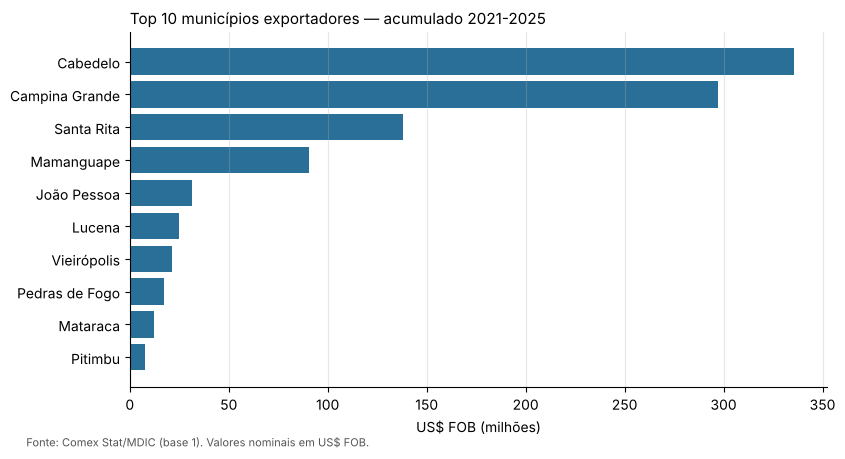

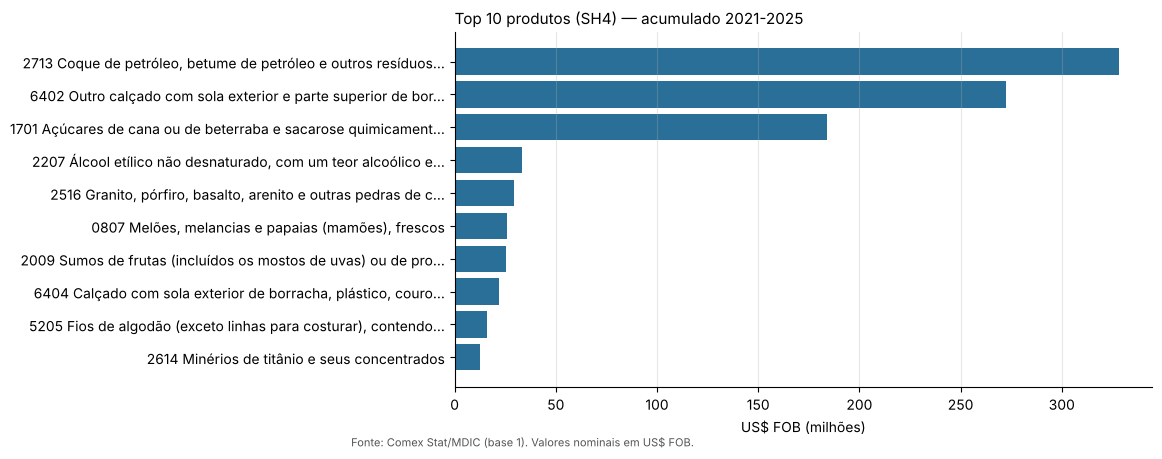

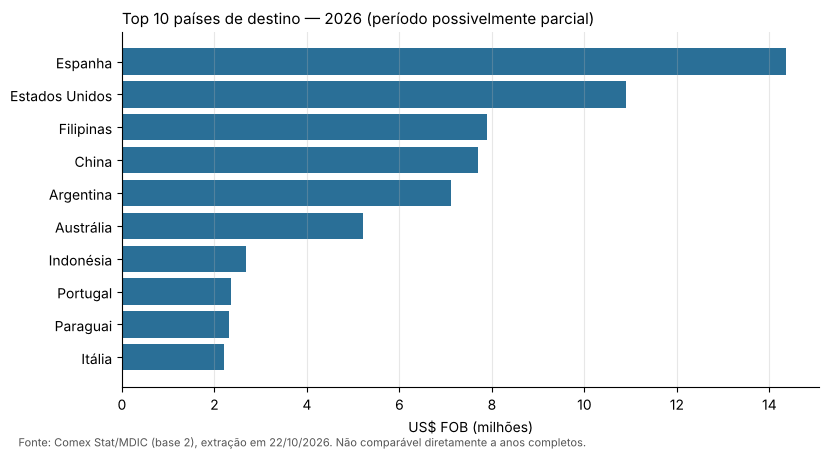

In [ ]:
# ------------------------------------------------------------------
# 5.7 Gráficos de apoio (salvos em relatorio/figuras/)
# ------------------------------------------------------------------
def barras(dados, rotulo, valor, titulo, arquivo, nota=None, max_rot=48):
    d = dados.iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 4.6))
    cortar = lambda t: t if len(t) <= max_rot else t[:max_rot].rstrip() + "…"
    ax.barh([cortar(str(x)) for x in d[rotulo]], d[valor] / 1e6, color="#2a6f97")
    ax.set_xlabel("US$ FOB (milhões)"); ax.set_title(titulo, fontsize=11, loc="left")
    if nota: fig.text(0.01, -0.02, nota, fontsize=8, color="#555")
    ax.grid(axis="x", alpha=.3); ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(PASTA_FIGURAS / arquivo, dpi=150, bbox_inches="tight"); plt.show()

barras(top_mun_2125, "municipio_nome", "fob_total_2021_2025", "Top 10 municípios exportadores — acumulado 2021-2025", "top_municipios_2021_2025.png",
       "Fonte: Comex Stat/MDIC (base 1). Valores nominais em US$ FOB.")
barras(top_produtos.head(10).assign(r=lambda d: d.sh4 + " " + d.descricao_sh4), "r", "fob_2021_2025", "Top 10 produtos (SH4) — acumulado 2021-2025", "top_produtos_2021_2025.png",
       "Fonte: Comex Stat/MDIC (base 1). Valores nominais em US$ FOB.", max_rot=60)
barras(top_paises.head(10), "pais", "fob_2026", "Top 10 países de destino — 2026 (período possivelmente parcial)", "top_paises_2026.png",
       f"Fonte: Comex Stat/MDIC (base 2), extração em {DATA_EXTRACAO:%d/%m/%Y}. Não comparável diretamente a anos completos.")

## Etapa 6 — Validação e integridade

Cada teste compara um valor **esperado** (calculado de forma independente, direto das bases originais `raw_A`/`raw_B`) com o valor **obtido** nas tabelas processadas. Ao final, o notebook **interrompe a execução se qualquer teste falhar**.

Grupos: **6.1** preservação dos originais · **6.2** contagens (perda de registros) · **6.3** totais antes × depois · **6.4** chaves e junções · **6.5** nulos, negativos e consistência.

In [ ]:
# ------------------------------------------------------------------
# 6.1 Preservação dos dados originais + conformidade com a aba "Detalhamento"
# ------------------------------------------------------------------
TESTES.clear()
sha_final = {k: sha256(v) for k, v in ARQUIVOS.items()}
testar("6.1 Preservação", "SHA-256 dos .xlsx originais idêntico ao registrado antes do tratamento", sha_final == HASH_INICIAL, "iguais", "iguais" if sha_final == HASH_INICIAL else "DIFERENTES")
testar("6.1 Preservação", "DataFrames raw_A e raw_B não foram modificados", assinatura(raw_A) == ASSINATURA_RAW["A"] and assinatura(raw_B) == ASSINATURA_RAW["B"], "assinaturas iguais", "ok")

for k, df in (("A", raw_A), ("B", raw_B)):
    d = DETALHAMENTO[k]
    testar("6.1 Detalhamento", f"Base {ROTULO[k]}: linhas lidas = 'Quantidade de linhas' declarada no Detalhamento", len(df) == int(d["Quantidade de linhas"]), d["Quantidade de linhas"], len(df))
    testar("6.1 Detalhamento", f"Base {ROTULO[k]}: fluxo = Exportação e consulta 'Por Município'", d["Fluxo"] == "Exportação" and d["Tipo de consulta"] == "Por Município", "Exportação / Por Município", f"{d['Fluxo']} / {d['Tipo de consulta']}")
testar("6.1 Detalhamento", "Base 1: anos do Detalhamento = anos das colunas", (int(DETALHAMENTO['A']['Ano inicial']), int(DETALHAMENTO['A']['Ano final'])) == (min(ANOS_A), max(ANOS_A)), (min(ANOS_A), max(ANOS_A)), (DETALHAMENTO['A']['Ano inicial'], DETALHAMENTO['A']['Ano final']))
testar("6.1 Detalhamento", "Base 2: anos do Detalhamento = anos das colunas", (int(DETALHAMENTO['B']['Ano inicial']), int(DETALHAMENTO['B']['Ano final'])) == (min(ANOS_B), max(ANOS_B)), (min(ANOS_B), max(ANOS_B)), (DETALHAMENTO['B']['Ano inicial'], DETALHAMENTO['B']['Ano final']))
testar("6.1 Detalhamento", "Filtro de UF = 25 (Paraíba) e todas as linhas com uf_sigla = PB", DETALHAMENTO["A"]["UF do Município"] == DETALHAMENTO["B"]["UF do Município"] == "25" and set(limpo_A.uf_sigla) | set(limpo_B.uf_sigla) == {"PB"}, "25 / {'PB'}", f"{DETALHAMENTO['A']['UF do Município']} / {set(limpo_A.uf_sigla) | set(limpo_B.uf_sigla)}")
print("Testes registrados até aqui:", len(TESTES))

Testes registrados até aqui: 9


In [ ]:
# ------------------------------------------------------------------
# 6.2 Contagens: houve perda de registros? As junções preservaram as observações?
# ------------------------------------------------------------------
n_unico_A = limpo_A["municipio_chave"].nunique(); n_unico_B = limpo_B["municipio_chave"].nunique()
conf_contagens = pd.DataFrame([
    ["Linhas da aba Resultado (originais)",                               len(raw_A), len(raw_B)],
    ["Linhas após limpeza (limpo_A / limpo_B)",                           len(limpo_A), len(limpo_B)],
    ["Células município x produto x ano (linhas x anos)",                 len(longo_A_completo), len(limpo_B) * len(ANOS_B)],
    ["(-) células sem registro (FOB=0 e kg=0) omitidas",                  -len(descartadas_A), -sem_reg_B],
    ["Observações nas tabelas de fato (tbl_mun_produto / tbl_mun_pais)",  len(tbl_mun_produto), len(tbl_mun_pais)],
    ["Municípios distintos na base",                                      n_unico_A, n_unico_B],
    ["Municípios na dimensão (união) / na consolidada",                   len(dim_municipio), len(consolidado)],
], columns=["etapa", "base 1 (2021-2025)", "base 2 (2026)"])
print("Conferência de contagens:"); display(conf_contagens)

testar("6.2 Contagens", "Limpeza não removeu linhas (base 1)", len(raw_A) == len(limpo_A), len(raw_A), len(limpo_A))
testar("6.2 Contagens", "Limpeza não removeu linhas (base 2)", len(raw_B) == len(limpo_B), len(raw_B), len(limpo_B))
testar("6.2 Contagens", "Formato longo: observações + células sem registro = linhas x anos", len(tbl_mun_produto) + len(descartadas_A) == len(raw_A) * len(ANOS_A), len(raw_A) * len(ANOS_A), len(tbl_mun_produto) + len(descartadas_A))
testar("6.2 Contagens", "Observações do longo = células com FOB>0 ou kg>0 contadas nos originais", len(tbl_mun_produto) == ACHADOS["celulas_com_registro_A"], ACHADOS["celulas_com_registro_A"], len(tbl_mun_produto))
testar("6.2 Contagens", "Células omitidas somam FOB=0 e kg=0 (nenhum valor positivo descartado)", descartadas_A[["valor_fob_usd", "kg_liquido"]].to_numpy().sum() == 0, 0, int(descartadas_A[["valor_fob_usd", "kg_liquido"]].to_numpy().sum()))
testar("6.2 Contagens", "Base 2: nenhuma linha perdida em tbl_mun_pais", len(tbl_mun_pais) == len(raw_B), len(raw_B), len(tbl_mun_pais))
testar("6.2 Contagens", "tbl_mun_ano = (município,ano) distintos das duas tabelas de fato", len(tbl_mun_ano) == tbl_mun_produto[["municipio_chave", "ano"]].drop_duplicates().shape[0] + tbl_mun_pais[["municipio_chave", "ano"]].drop_duplicates().shape[0], "soma dos pares distintos", len(tbl_mun_ano))

Conferência de contagens:


,etapa,base 1 (2021-2025),base 2 (2026)
0,Linhas da aba Resultado (originais),436,154
1,Linhas após limpeza (limpo_A / limpo_B),436,154
2,Células município x produto x ano (linhas x anos),2180,154
3,(-) células sem registro (FOB=0 e kg=0) omitidas,-1351,0
4,Observações nas tabelas de fato (tbl_mun_produto / tbl_mun_pais),829,154
5,Municípios distintos na base,48,25
6,Municípios na dimensão (união) / na consolidada,48,48


In [ ]:
# ------------------------------------------------------------------
# 6.3 Totais antes x depois (esperado = soma direta das colunas ORIGINAIS convertidas, independente da limpeza)
# ------------------------------------------------------------------
linhas = []
def conferir(base, df_raw, ano, tbl_fato, nome_fato, pref):   # nome_fato: nome da tabela de fato usada na base
    for medida, c_raw, c_t, p in (("FOB (US$)", col_fob(ano), "valor_fob_usd", "fob"), ("Quilograma líquido", col_kg(ano), "kg_liquido", "kg")):
        orig = int(pd.to_numeric(df_raw[c_raw]).sum())
        fato = int(tbl_fato.loc[tbl_fato.ano == ano, c_t].sum())
        mano = int(tbl_mun_ano.loc[tbl_mun_ano.ano == ano, c_t].sum())
        cons = int(consolidado[f"{p}_{ano}"].sum())
        linhas.append({"base": base, "ano": ano, "medida": medida, "tabela de fato": nome_fato, "original (xlsx)": orig, "após transformação (fato)": fato,
                       "tbl_mun_ano": mano, "consolidado": cons,
                       "dif_máx_abs": max(abs(fato - orig), abs(mano - orig), abs(cons - orig))})
for ano in ANOS_A: conferir("1", raw_A, ano, tbl_mun_produto, "tbl_mun_produto", None)
for ano in ANOS_B: conferir("2", raw_B, ano, tbl_mun_pais, "tbl_mun_pais", None)
conf_totais = pd.DataFrame(linhas)
print("Conferência de totais por ano — original x tabelas processadas:"); display(conf_totais)

testar("6.3 Totais", "Totais anuais de FOB e kg: original = tbl de fato = tbl_mun_ano = consolidado (todos os anos, ambas as bases)", (conf_totais["dif_máx_abs"] == 0).all(), "diferença 0 em todas as linhas", f"dif máxima = {conf_totais['dif_máx_abs'].max()}")

tot_prod_orig = sum(int(pd.to_numeric(raw_A[col_fob(a)]).sum()) for a in ANOS_A)
testar("6.3 Totais", "FOB acumulado 2021-2025: original = consolidado.fob_total_2021_2025", int(consolidado.fob_total_2021_2025.sum()) == tot_prod_orig, tot_prod_orig, int(consolidado.fob_total_2021_2025.sum()))
kg_prod_orig = sum(int(pd.to_numeric(raw_A[col_kg(a)]).sum()) for a in ANOS_A)
testar("6.3 Totais", "Kg acumulado 2021-2025: original = consolidado.kg_total_2021_2025", int(consolidado.kg_total_2021_2025.sum()) == kg_prod_orig, kg_prod_orig, int(consolidado.kg_total_2021_2025.sum()))
testar("6.3 Totais", "FOB 2026: original = consolidado.fob_2026 (a junção não duplicou valores)", int(consolidado.fob_2026.sum()) == int(pd.to_numeric(raw_B[col_fob(ANO_B)]).sum()), int(pd.to_numeric(raw_B[col_fob(ANO_B)]).sum()), int(consolidado.fob_2026.sum()))

# Recomputação independente por município direto do formato largo (sem passar pelo formato longo)
ind_A = limpo_A.groupby("municipio_chave")[[col_fob(a) for a in ANOS_A]].sum().sum(axis=1)
cmp_A = consolidado.set_index("municipio_chave").fob_total_2021_2025.astype(float).fillna(0).reindex(ind_A.index)
testar("6.3 Totais", "FOB 2021-2025 por município: recomputação direta do formato largo = consolidado (todos os municípios)", np.allclose(ind_A.values, cmp_A.values), "0 divergências", int((~np.isclose(ind_A.values, cmp_A.values)).sum()))
ind_B = limpo_B.groupby("municipio_chave")[col_fob(ANO_B)].sum()
cmp_B = consolidado.set_index("municipio_chave").fob_2026.astype(float).fillna(0).reindex(ind_B.index)
testar("6.3 Totais", "FOB 2026 por município: recomputação direta da base 2 = consolidado", np.allclose(ind_B.values, cmp_B.values), "0 divergências", int((~np.isclose(ind_B.values, cmp_B.values)).sum()))
testar("6.3 Totais", "Soma dos produtos (top_produtos) = FOB 2021-2025 total", int(top_produtos.fob_2021_2025.sum()) == tot_prod_orig, tot_prod_orig, int(top_produtos.fob_2021_2025.sum()))
testar("6.3 Totais", "Soma dos países (top_paises) = FOB 2026 total", int(top_paises.fob_2026.sum()) == int(pd.to_numeric(raw_B[col_fob(ANO_B)]).sum()), int(pd.to_numeric(raw_B[col_fob(ANO_B)]).sum()), int(top_paises.fob_2026.sum()))

# Rankings coerentes com cálculo independente
mun_top_ind = limpo_A.assign(t=limpo_A[[col_fob(a) for a in ANOS_A]].sum(axis=1)).groupby("municipio_nome").t.sum().idxmax()
testar("6.3 Totais", "Município nº 1 (2021-2025) = cálculo independente", consolidado.loc[consolidado.rank_fob_2021_2025 == 1, "municipio_nome"].iloc[0] == mun_top_ind, mun_top_ind, consolidado.loc[consolidado.rank_fob_2021_2025 == 1, "municipio_nome"].iloc[0])
prod_top_ind = limpo_A.assign(t=limpo_A[[col_fob(a) for a in ANOS_A]].sum(axis=1)).groupby("sh4").t.sum().idxmax()
testar("6.3 Totais", "Produto SH4 nº 1 (2021-2025) = cálculo independente", top_produtos.sh4.iloc[0] == prod_top_ind, prod_top_ind, top_produtos.sh4.iloc[0])
pais_top_ind = limpo_B.groupby("pais")[col_fob(ANO_B)].sum().idxmax()
testar("6.3 Totais", "País nº 1 (2026) = cálculo independente", top_paises.pais.iloc[0] == pais_top_ind, pais_top_ind, top_paises.pais.iloc[0])

Conferência de totais por ano — original x tabelas processadas:


,base,ano,medida,tabela de fato,original (xlsx),após transformação (fato),tbl_mun_ano,consolidado,dif_máx_abs
0,1,2021,FOB (US$),tbl_mun_produto,184492144,184492144,184492144,184492144,0
1,1,2021,Quilograma líquido,tbl_mun_produto,406974821,406974821,406974821,406974821,0
2,1,2022,FOB (US$),tbl_mun_produto,265709342,265709342,265709342,265709342,0
3,1,2022,Quilograma líquido,tbl_mun_produto,446878652,446878652,446878652,446878652,0
4,1,2023,FOB (US$),tbl_mun_produto,257599016,257599016,257599016,257599016,0
5,1,2023,Quilograma líquido,tbl_mun_produto,473102910,473102910,473102910,473102910,0
6,1,2024,FOB (US$),tbl_mun_produto,171810019,171810019,171810019,171810019,0
7,1,2024,Quilograma líquido,tbl_mun_produto,389234617,389234617,389234617,389234617,0
8,1,2025,FOB (US$),tbl_mun_produto,141410800,141410800,141410800,141410800,0
9,1,2025,Quilograma líquido,tbl_mun_produto,189496504,189496504,189496504,189496504,0


In [ ]:
# ------------------------------------------------------------------
# 6.4 Chaves e junções: unicidade, correspondência e ausência de duplicação
# ------------------------------------------------------------------
dimk = set(dim_municipio.municipio_chave)
conf_chaves = pd.DataFrame({
    "item": ["Chaves distintas na base 1", "Chaves distintas na base 2", "Interseção (em ambas)", "Somente na base 1", "Somente na base 2",
             "União = linhas de dim_municipio = linhas do consolidado"],
    "esperado (conjuntos)": [n_unico_A, n_unico_B, len(set(limpo_A.municipio_chave) & set(limpo_B.municipio_chave)),
                             len(set(limpo_A.municipio_chave) - set(limpo_B.municipio_chave)),
                             len(set(limpo_B.municipio_chave) - set(limpo_A.municipio_chave)),
                             len(set(limpo_A.municipio_chave) | set(limpo_B.municipio_chave))],
    "obtido (tabelas)": [int(dim_municipio.n_linhas_base1.notna().sum()), int(dim_municipio.n_linhas_base2.notna().sum()),
                         ACHADOS["n_mun_ambas"], ACHADOS["n_mun_so_A"], ACHADOS["n_mun_so_B"], len(consolidado)]})
conf_chaves["confere"] = conf_chaves["esperado (conjuntos)"] == conf_chaves["obtido (tabelas)"]
print("Conferência de chaves municipais:"); display(conf_chaves)
testar("6.4 Chaves", "Contagens de chaves (base 1, base 2, ambas, só 1, só 2, união) conferem com os conjuntos", conf_chaves["confere"].all(), "6 conferências OK", f"{int(conf_chaves['confere'].sum())} OK")
testar("6.4 Chaves", "dim_municipio e consolidado: uma linha por município (chave única)", dim_municipio.municipio_chave.is_unique and consolidado.municipio_chave.is_unique, "únicas", "únicas")
testar("6.4 Chaves", "Sem chaves órfãs: toda chave das tabelas de fato existe em dim_municipio", set(tbl_mun_produto.municipio_chave) <= dimk and set(tbl_mun_pais.municipio_chave) <= dimk and set(tbl_mun_ano.municipio_chave) <= dimk, "0 órfãs", 0)
testar("6.4 Chaves", "Chaves sem correspondência estão documentadas em presenca_bases (só base 1 / só base 2)", (consolidado.presenca_bases != MAPA_PRESENCA["both"]).sum() == ACHADOS["n_mun_so_A"] + ACHADOS["n_mun_so_B"], ACHADOS["n_mun_so_A"] + ACHADOS["n_mun_so_B"], int((consolidado.presenca_bases != MAPA_PRESENCA["both"]).sum()))
testar("6.4 Chaves", "Municípios 'somente base 1' têm 2026 vazio (NaN, não zero) — nº de NaN em fob_2026", consolidado.fob_2026.isna().sum() == ACHADOS["n_mun_so_A"], ACHADOS["n_mun_so_A"], int(consolidado.fob_2026.isna().sum()))
testar("6.4 Chaves", "Municípios 'somente base 2' têm 2021-2025 vazio — nº de NaN em fob_total_2021_2025", consolidado.fob_total_2021_2025.isna().sum() == ACHADOS["n_mun_so_B"], ACHADOS["n_mun_so_B"], int(consolidado.fob_total_2021_2025.isna().sum()))
testar("6.4 Chaves", "Sem duplicatas de chave natural: (município,SH4,ano), (município,país) e (município,ano)",
       not tbl_mun_produto.duplicated(["municipio_chave", "sh4", "ano"]).any() and not tbl_mun_pais.duplicated(["municipio_chave", "pais"]).any() and not tbl_mun_ano.duplicated(["municipio_chave", "ano"]).any(),
       "0 duplicatas", int(tbl_mun_produto.duplicated(["municipio_chave", "sh4", "ano"]).sum() + tbl_mun_pais.duplicated(["municipio_chave", "pais"]).sum() + tbl_mun_ano.duplicated(["municipio_chave", "ano"]).sum()))
testar("6.4 Chaves", "Nenhuma combinação artificial produto x país: nenhuma tabela tem as colunas sh4 e pais juntas", all(not ({"sh4", "pais"} <= set(t.columns)) for t in (tbl_mun_produto, tbl_mun_pais, tbl_mun_ano, consolidado)), "sem sh4+pais na mesma tabela", "ok")

Conferência de chaves municipais:


,item,esperado (conjuntos),obtido (tabelas),confere
0,Chaves distintas na base 1,48,48,True
1,Chaves distintas na base 2,25,25,True
2,Interseção (em ambas),25,25,True
3,Somente na base 1,23,23,True
4,Somente na base 2,0,0,True
5,União = linhas de dim_municipio = linhas do consolidado,48,48,True


In [ ]:
# ------------------------------------------------------------------
# 6.5 Nulos, negativos e consistência interna após o tratamento
# ------------------------------------------------------------------
def nulos_por_coluna(df, nome):
    s = df.isna().sum(); s = s[s > 0]
    return pd.DataFrame({"tabela": nome, "coluna": s.index, "nulos": s.values, "linhas": len(df)})

conf_nulos = pd.concat([nulos_por_coluna(tbl_mun_produto, "tbl_mun_produto"), nulos_por_coluna(tbl_mun_pais, "tbl_mun_pais"),
                        nulos_por_coluna(tbl_mun_ano, "tbl_mun_ano"), nulos_por_coluna(consolidado, "consolidado")], ignore_index=True)
conf_nulos["explicação"] = conf_nulos.apply(lambda r: "preço indefinido (kg=0)" if r.coluna.startswith("preco") and r.tabela != "consolidado"
    else "município sem registro no período (ausência de registro, não zero)", axis=1)
print("Nulos remanescentes (todos esperados e explicados):"); display(conf_nulos)

CHAVES_E_MEDIDAS = {"tbl_mun_produto": (tbl_mun_produto, ["municipio_chave", "sh4", "ano", "valor_fob_usd", "kg_liquido"]),
                    "tbl_mun_pais": (tbl_mun_pais, ["municipio_chave", "pais", "ano", "valor_fob_usd", "kg_liquido"]),
                    "tbl_mun_ano": (tbl_mun_ano, ["municipio_chave", "ano", "valor_fob_usd", "kg_liquido"])}
n_nulos_obrig = sum(int(df[cols].isna().sum().sum()) for df, cols in CHAVES_E_MEDIDAS.values())
testar("6.5 Valores", "Sem nulos em chaves, ano, FOB e kg das tabelas de fato", n_nulos_obrig == 0, 0, n_nulos_obrig)
n_neg = sum(int((df[["valor_fob_usd", "kg_liquido"]] < 0).sum().sum()) for df, _ in CHAVES_E_MEDIDAS.values())
testar("6.5 Valores", "Sem valores negativos de FOB ou kg", n_neg == 0, 0, n_neg)
testar("6.5 Valores", "FOB e kg são inteiros (dtype int64) nas tabelas de fato", all(str(df[c].dtype) == "int64" for df, _ in CHAVES_E_MEDIDAS.values() for c in ("valor_fob_usd", "kg_liquido")), "int64", "int64")
testar("6.5 Valores", "Preço médio indefinido (NaN) exatamente onde kg=0 (base 1)", (tbl_mun_produto.preco_medio_usd_kg.isna() == (tbl_mun_produto.kg_liquido == 0)).all(), "NaN <=> kg=0", f"{ACHADOS['preco_nan_A']} NaN")
testar("6.5 Valores", "Preço médio indefinido (NaN) exatamente onde kg=0 (base 2)", (tbl_mun_pais.preco_medio_usd_kg.isna() == (tbl_mun_pais.kg_liquido == 0)).all(), "NaN <=> kg=0", f"{ACHADOS['preco_nan_B']} NaN")
testar("6.5 Valores", "Nenhum preço infinito ou negativo", np.isfinite(tbl_mun_produto.preco_medio_usd_kg.dropna()).all() and np.isfinite(tbl_mun_pais.preco_medio_usd_kg.dropna()).all() and (tbl_mun_produto.preco_medio_usd_kg.dropna() >= 0).all(), "finitos e >= 0", "ok")
testar("6.5 Valores", "Casos FOB>0 e kg=0 nas tabelas = contagem do diagnóstico (base 1 e 2)", int(((tbl_mun_produto.valor_fob_usd > 0) & (tbl_mun_produto.kg_liquido == 0)).sum()) == ACHADOS["fob_pos_kg_zero_A"] and int(((tbl_mun_pais.valor_fob_usd > 0) & (tbl_mun_pais.kg_liquido == 0)).sum()) == ACHADOS["fob_pos_kg_zero_B"], f"{ACHADOS['fob_pos_kg_zero_A']} e {ACHADOS['fob_pos_kg_zero_B']}", "iguais")

# Participações: somam 100% no grupo correto
tot_g = tbl_mun_produto.groupby(["municipio_chave", "ano"]).valor_fob_usd.sum()
soma_g = tbl_mun_produto.groupby(["municipio_chave", "ano"]).part_produto_no_municipio_ano_pct.sum()
testar("6.5 Participações", "Produtos: participações somam 100% em cada município-ano (com FOB>0)", np.allclose(soma_g[tot_g > 0], 100), "100%", f"min {soma_g[tot_g > 0].min():.6f} / máx {soma_g[tot_g > 0].max():.6f}")
soma_pB = tbl_mun_pais.groupby("municipio_chave").part_pais_no_municipio_pct.sum()
testar("6.5 Participações", "Países: participações somam 100% em cada município (2026)", np.allclose(soma_pB, 100), "100%", f"min {soma_pB.min():.6f} / máx {soma_pB.max():.6f}")
testar("6.5 Participações", "Municípios: participações somam 100% em cada ano (tbl_mun_ano)", np.allclose(tbl_mun_ano.groupby("ano").part_municipio_no_total_ano_pct.sum(), 100), "100%", "ok")
testar("6.5 Participações", "Consolidado: part_estado 2021-2025 e 2026 somam 100%", np.isclose(consolidado.part_estado_fob_2021_2025_pct.sum(), 100) and np.isclose(consolidado.part_estado_fob_2026_pct.sum(), 100), "100% e 100%", f"{consolidado.part_estado_fob_2021_2025_pct.sum():.6f} e {consolidado.part_estado_fob_2026_pct.sum():.6f}")
testar("6.5 Participações", "Países: part_no_total_estado_2026 soma 100%", np.isclose(tbl_mun_pais.part_no_total_estado_2026_pct.sum(), 100), "100%", f"{tbl_mun_pais.part_no_total_estado_2026_pct.sum():.6f}")
testar("6.5 Participações", "Todas as participações estão em [0, 100]", all(((s.dropna() >= 0) & (s.dropna() <= 100 + 1e-9)).all() for s in (tbl_mun_produto.part_produto_no_municipio_ano_pct, tbl_mun_pais.part_pais_no_municipio_pct, tbl_mun_ano.part_municipio_no_total_ano_pct, consolidado.part_estado_fob_2021_2025_pct, consolidado.part_estado_fob_2026_pct, consolidado.part_produto_principal_pct, consolidado.part_pais_principal_pct)), "0 a 100", "ok")
testar("6.5 Consistência", "Período 2026 marcado como possivelmente parcial; 2021-2025 como completos", bool(tbl_mun_pais.periodo_possivelmente_parcial.all()) and not tbl_mun_ano.loc[tbl_mun_ano.ano.isin(ANOS_A), "periodo_possivelmente_parcial"].any(), "2026=True; 2021-2025=False", "ok")

Nulos remanescentes (todos esperados e explicados):


,tabela,coluna,nulos,linhas,explicação
0,tbl_mun_produto,preco_medio_usd_kg,52,829,preço indefinido (kg=0)
1,tbl_mun_pais,preco_medio_usd_kg,3,154,preço indefinido (kg=0)
2,tbl_mun_ano,preco_medio_usd_kg,5,180,preço indefinido (kg=0)
3,consolidado,fob_2021,19,48,"município sem registro no período (ausência de registro, não zero)"
4,consolidado,fob_2022,16,48,"município sem registro no período (ausência de registro, não zero)"
5,consolidado,fob_2023,15,48,"município sem registro no período (ausência de registro, não zero)"
6,consolidado,fob_2024,17,48,"município sem registro no período (ausência de registro, não zero)"
7,consolidado,fob_2025,18,48,"município sem registro no período (ausência de registro, não zero)"
8,consolidado,kg_2021,19,48,"município sem registro no período (ausência de registro, não zero)"
9,consolidado,kg_2022,16,48,"município sem registro no período (ausência de registro, não zero)"


In [ ]:
# ------------------------------------------------------------------
# 6.6 Resultado dos testes — a execução é interrompida se algum falhar
# ------------------------------------------------------------------
df_testes = pd.DataFrame(TESTES)
display(df_testes.groupby("grupo").agg(testes=("status", "size"), ok=("status", lambda s: int((s == "OK").sum()))))
display(df_testes[["grupo", "teste", "esperado", "obtido", "status"]])
falhas = df_testes[df_testes.status != "OK"]
assert falhas.empty, f"{len(falhas)} teste(s) falharam:\n{falhas[['teste','esperado','obtido']]}"
print(f"\n✅ {len(df_testes)} testes de integridade aprovados.")

,testes,ok
grupo,,
6.1 Detalhamento,7,7
6.1 Preservação,2,2
6.2 Contagens,7,7
6.3 Totais,11,11
6.4 Chaves,8,8
6.5 Consistência,1,1
6.5 Participações,6,6
6.5 Valores,7,7


,grupo,teste,esperado,obtido,status
0,6.1 Preservação,SHA-256 dos .xlsx originais idêntico ao registrado antes do tratam...,iguais,iguais,OK
1,6.1 Preservação,DataFrames raw_A e raw_B não foram modificados,assinaturas iguais,ok,OK
2,6.1 Detalhamento,Base 1: linhas lidas = 'Quantidade de linhas' declarada no Detalha...,436,436,OK
3,6.1 Detalhamento,Base 1: fluxo = Exportação e consulta 'Por Município',Exportação / Por Município,Exportação / Por Município,OK
4,6.1 Detalhamento,Base 2: linhas lidas = 'Quantidade de linhas' declarada no Detalha...,154,154,OK
5,6.1 Detalhamento,Base 2: fluxo = Exportação e consulta 'Por Município',Exportação / Por Município,Exportação / Por Município,OK
6,6.1 Detalhamento,Base 1: anos do Detalhamento = anos das colunas,"(2021, 2025)","('2021', '2025')",OK
7,6.1 Detalhamento,Base 2: anos do Detalhamento = anos das colunas,"(2026, 2026)","('2026', '2026')",OK
8,6.1 Detalhamento,Filtro de UF = 25 (Paraíba) e todas as linhas com uf_sigla = PB,25 / {'PB'},25 / {'PB'},OK
9,6.2 Contagens,Limpeza não removeu linhas (base 1),436,436,OK



✅ 49 testes de integridade aprovados.


## Etapa 7 — Exportação dos resultados e resumo das decisões

**7.1** Dicionário de dados (validado contra as colunas reais) · **7.2** Exportação dos CSV + conferência de reimportação · **7.3** Relatório de qualidade · **7.4** Relatório em MD/PDF, Excel e README · **7.5** Logs e resumo final.

In [ ]:
# ------------------------------------------------------------------
# 7.1 Dicionário de dados atualizado (um registro por variável de cada tabela exportada)
# ------------------------------------------------------------------
DIC = []
def dic(tabela, itens):
    for v, t, u, d, o in itens:
        DIC.append({"tabela": tabela, "variavel": v, "tipo": t, "unidade": u, "descricao": d, "origem_ou_formula": o})

_geo = lambda base: [
    ("uf_sigla", "texto", "-", "Sigla da UF do município", f"{base}: sufixo ' - UF' de 'Município'; conferida com 'UF do Município'"),
    ("municipio_nome", "texto", "-", "Nome do município (sem o sufixo de UF)", f"{base}: 'Município' sem ' - UF', espaços normalizados"),
    ("municipio_chave", "texto", "-", "Chave de relacionamento entre as bases: nome sem acento e em minúsculas + '|' + UF (ex.: 'campina grande|pb'). Não é o código IBGE (ausente nas fontes)", "derivada de municipio_nome e uf_sigla")]

dic("exportacoes_municipio_produto_2021_2025", _geo("Base 1") + [
    ("sh4", "texto (4 dígitos)", "-", "Código SH4 (Sistema Harmonizado). Guardado como TEXTO para preservar zeros à esquerda (ler com dtype=str)", "'Código SH4' padronizado com 4 dígitos"),
    ("descricao_sh4", "texto", "-", "Descrição oficial da posição SH4 (uma por código)", "'Descrição SH4', espaços normalizados"),
    ("capitulo_sh2", "texto (2 dígitos)", "-", "Capítulo do SH (dois primeiros dígitos do SH4)", "sh4[:2]"),
    ("ano", "inteiro", "ano", "Ano de referência (2021 a 2025, anos completos)", "ano extraído do nome das colunas '<ano> - ...'"),
    ("valor_fob_usd", "inteiro", "US$ FOB correntes", "Valor exportado (nominal, sem deflacionar)", "coluna '<ano> - Valor US$ FOB'"),
    ("kg_liquido", "inteiro", "quilograma", "Peso líquido exportado", "coluna '<ano> - Quilograma Líquido'"),
    ("preco_medio_usd_kg", "decimal", "US$ por kg", "Preço médio implícito; vazio quando kg_liquido = 0 (indefinido). Comparável apenas dentro do mesmo SH4", "valor_fob_usd / kg_liquido (se kg_liquido > 0)"),
    ("part_produto_no_municipio_ano_pct", "decimal", "%", "Participação do produto no FOB do município no ano", "100 * valor_fob_usd / soma do FOB do município no ano")])

dic("exportacoes_municipio_pais_2026", _geo("Base 2") + [
    ("pais", "texto", "-", "País de destino, grafia da fonte (sem código ISO nas planilhas)", "'País', espaços normalizados"),
    ("ano", "inteiro", "ano", "Ano de referência (2026) — período possivelmente parcial", "ano das colunas '2026 - ...'"),
    ("valor_fob_usd", "inteiro", "US$ FOB correntes", "Valor exportado no período", "coluna '2026 - Valor US$ FOB'"),
    ("kg_liquido", "inteiro", "quilograma", "Peso líquido exportado no período", "coluna '2026 - Quilograma Líquido'"),
    ("preco_medio_usd_kg", "decimal", "US$ por kg", "Preço médio implícito; vazio quando kg_liquido = 0", "valor_fob_usd / kg_liquido (se kg_liquido > 0)"),
    ("part_pais_no_municipio_pct", "decimal", "%", "Participação do país no FOB do município em 2026", "100 * valor_fob_usd / soma do FOB do município"),
    ("part_no_total_estado_2026_pct", "decimal", "%", "Participação do par município-país no FOB total da Paraíba em 2026", "100 * valor_fob_usd / soma do FOB de 2026"),
    ("periodo_possivelmente_parcial", "lógico", "-", "True quando a extração (22/10/2026) ocorreu antes do fim do ano: não comparar diretamente com anos completos", "data da extração < 31/12 do ano")])

dic("exportacoes_municipio_ano", _geo("Bases 1 e 2") + [
    ("ano", "inteiro", "ano", "Ano de referência (2021 a 2026)", "tbl_mun_produto e tbl_mun_pais"),
    ("base_origem", "texto", "-", "Base de onde vem o total do ano (2021-2025: base 1; 2026: base 2)", "constante por ano"),
    ("valor_fob_usd", "inteiro", "US$ FOB correntes", "Total exportado pelo município no ano", "soma de valor_fob_usd da tabela de fato"),
    ("kg_liquido", "inteiro", "quilograma", "Peso líquido total do município no ano", "soma de kg_liquido da tabela de fato"),
    ("preco_medio_usd_kg", "decimal", "US$ por kg", "Razão dos totais (média ponderada); vazio quando kg = 0", "valor_fob_usd / kg_liquido (se kg > 0)"),
    ("part_municipio_no_total_ano_pct", "decimal", "%", "Participação do município no FOB total da Paraíba no ano", "100 * valor_fob_usd / soma do FOB do ano"),
    ("periodo_possivelmente_parcial", "lógico", "-", "True para 2026 (possivelmente parcial)", "data da extração < 31/12 do ano")])

_cons = [
    ("presenca_bases", "texto", "-", "Presença do município: 'Ambas as bases', 'Somente 2021-2025 (base 1)' ou 'Somente 2026 (base 2)'", "união (outer join um-para-um) das chaves; indicator=True")]
for a in ANOS_A: _cons.append((f"fob_{a}", "inteiro anulável", "US$ FOB correntes", f"FOB do município em {a}; vazio = sem registro no ano (não é zero)", f"soma de tbl_mun_produto em {a}"))
for a in ANOS_A: _cons.append((f"kg_{a}", "inteiro anulável", "quilograma", f"Peso líquido do município em {a}; vazio = sem registro", f"soma de tbl_mun_produto em {a}"))
_cons += [
    ("fob_total_2021_2025", "inteiro anulável", "US$ FOB correntes", "FOB acumulado 2021-2025", "soma de fob_2021..fob_2025 (anos sem registro ignorados)"),
    ("kg_total_2021_2025", "inteiro anulável", "quilograma", "Peso líquido acumulado 2021-2025", "soma de kg_2021..kg_2025"),
    ("preco_medio_2021_2025_usd_kg", "decimal", "US$ por kg", "Preço médio ponderado do período (razão dos totais)", "fob_total_2021_2025 / kg_total_2021_2025"),
    ("part_estado_fob_2021_2025_pct", "decimal", "%", "Participação do município no FOB acumulado da Paraíba (2021-2025)", "100 * fob_total_2021_2025 / soma"),
    ("rank_fob_2021_2025", "inteiro anulável", "posição", "Ranking por FOB acumulado 2021-2025 (1 = maior)", "rank decrescente, método 'min'"),
    ("anos_com_registro_2021_2025", "inteiro anulável", "anos", "Nº de anos (2021-2025) com algum registro de exportação", "contagem de fob_<ano> não vazios"),
    ("n_produtos_sh4_2021_2025", "inteiro anulável", "unidades", "Nº de produtos SH4 distintos com registro em 2021-2025", "contagem distinta de sh4 em tbl_mun_produto"),
    ("produto_principal_sh4", "texto (4 dígitos)", "-", "SH4 de maior FOB acumulado 2021-2025 no município (desempate: menor código)", "argmax por município"),
    ("produto_principal_descricao", "texto", "-", "Descrição do produto principal", "descricao_sh4 do produto principal"),
    ("part_produto_principal_pct", "decimal", "%", "Participação do produto principal no FOB acumulado do município", "100 * FOB do produto / fob_total_2021_2025"),
    ("fob_2026", "inteiro anulável", "US$ FOB correntes", "FOB de 2026 (possivelmente parcial); vazio = sem registro na base 2 (não é zero)", "soma de tbl_mun_pais"),
    ("kg_2026", "inteiro anulável", "quilograma", "Peso líquido de 2026 (possivelmente parcial)", "soma de tbl_mun_pais"),
    ("preco_medio_2026_usd_kg", "decimal", "US$ por kg", "Preço médio ponderado de 2026", "fob_2026 / kg_2026 (se kg > 0)"),
    ("part_estado_fob_2026_pct", "decimal", "%", "Participação do município no FOB de 2026 da Paraíba", "100 * fob_2026 / soma"),
    ("rank_fob_2026", "inteiro anulável", "posição", "Ranking por FOB de 2026 (1 = maior)", "rank decrescente, método 'min'"),
    ("n_paises_2026", "inteiro anulável", "unidades", "Nº de países de destino distintos em 2026", "contagem distinta de pais em tbl_mun_pais"),
    ("pais_principal_2026", "texto", "-", "País de maior FOB em 2026 para o município (desempate: ordem alfabética)", "argmax por município"),
    ("part_pais_principal_pct", "decimal", "%", "Participação do país principal no FOB 2026 do município", "100 * FOB do país / fob_2026")]
dic("exportacoes_municipio_consolidado", _geo("Bases 1 e 2") + _cons)

dicionario = pd.DataFrame(DIC)

SAIDAS = {"exportacoes_municipio_produto_2021_2025": tbl_mun_produto,
          "exportacoes_municipio_pais_2026": tbl_mun_pais,
          "exportacoes_municipio_consolidado": consolidado,
          "exportacoes_municipio_ano": tbl_mun_ano}

# O dicionário precisa corresponder EXATAMENTE (nomes e ordem) às colunas exportadas
for nome, df in SAIDAS.items():
    vars_dic = dicionario.loc[dicionario.tabela == nome, "variavel"].tolist()
    testar("7.1 Dicionário", f"Dicionário = colunas de {nome}", vars_dic == list(df.columns), f"{len(df.columns)} variáveis", f"{len(vars_dic)} no dicionário")
assert all(t["status"] == "OK" for t in TESTES), [t for t in TESTES if t["status"] != "OK"]
print(f"Dicionário: {len(dicionario)} variáveis em {dicionario.tabela.nunique()} tabelas — correspondência exata com as colunas exportadas.")
display(dicionario.head(10))

Dicionário: 64 variáveis em 4 tabelas — correspondência exata com as colunas exportadas.


,tabela,variavel,tipo,unidade,descricao,origem_ou_formula
0,exportacoes_municipio_produto_2021_2025,uf_sigla,texto,-,Sigla da UF do município,Base 1: sufixo ' - UF' de 'Município'; conferida com 'UF do Municí...
1,exportacoes_municipio_produto_2021_2025,municipio_nome,texto,-,Nome do município (sem o sufixo de UF),"Base 1: 'Município' sem ' - UF', espaços normalizados"
2,exportacoes_municipio_produto_2021_2025,municipio_chave,texto,-,Chave de relacionamento entre as bases: nome sem acento e em minús...,derivada de municipio_nome e uf_sigla
3,exportacoes_municipio_produto_2021_2025,sh4,texto (4 dígitos),-,Código SH4 (Sistema Harmonizado). Guardado como TEXTO para preserv...,'Código SH4' padronizado com 4 dígitos
4,exportacoes_municipio_produto_2021_2025,descricao_sh4,texto,-,Descrição oficial da posição SH4 (uma por código),"'Descrição SH4', espaços normalizados"
5,exportacoes_municipio_produto_2021_2025,capitulo_sh2,texto (2 dígitos),-,Capítulo do SH (dois primeiros dígitos do SH4),sh4[:2]
6,exportacoes_municipio_produto_2021_2025,ano,inteiro,ano,"Ano de referência (2021 a 2025, anos completos)",ano extraído do nome das colunas '<ano> - ...'
7,exportacoes_municipio_produto_2021_2025,valor_fob_usd,inteiro,US$ FOB correntes,"Valor exportado (nominal, sem deflacionar)",coluna '<ano> - Valor US$ FOB'
8,exportacoes_municipio_produto_2021_2025,kg_liquido,inteiro,quilograma,Peso líquido exportado,coluna '<ano> - Quilograma Líquido'
9,exportacoes_municipio_produto_2021_2025,preco_medio_usd_kg,decimal,US$ por kg,Preço médio implícito; vazio quando kg_liquido = 0 (indefinido). C...,valor_fob_usd / kg_liquido (se kg_liquido > 0)


In [ ]:
# ------------------------------------------------------------------
# 7.2 Exportação dos arquivos processados (CSV UTF-8 com BOM, separador ',', decimal '.') + conferência de reimportação
# ------------------------------------------------------------------
COLS_TEXTO_COM_ZERO = {"sh4": str, "produto_principal_sh4": str, "capitulo_sh2": str}   # leitura correta dos códigos

def exportar_csv(df, nome):
    caminho = PASTA_TRATADOS / f"{nome}.csv"
    df.to_csv(caminho, index=False, encoding="utf-8-sig")
    return caminho

def conferir_csv(df, caminho):
    r = pd.read_csv(caminho, dtype=COLS_TEXTO_COM_ZERO)
    ok = r.shape == df.shape and list(r.columns) == list(df.columns)
    for c in df.columns:
        if pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            ok &= np.allclose(df[c].astype(float).fillna(-1).to_numpy(), r[c].astype(float).fillna(-1).to_numpy(), rtol=1e-12, atol=0)
        else:
            ok &= df[c].fillna("").astype(str).reset_index(drop=True).equals(r[c].fillna("").astype(str).reset_index(drop=True))
    return bool(ok)

arquivos_gerados = []
for nome, df in SAIDAS.items():
    caminho = exportar_csv(df, nome)
    ok = conferir_csv(df, caminho)
    testar("7.2 Exportação", f"Reimportação de {caminho.name} idêntica à tabela em memória (incl. sh4 como texto)", ok, "idêntica", "idêntica" if ok else "DIVERGE")
    arquivos_gerados.append(caminho.name)
    print(f"{caminho.name:55s} {df.shape[0]:>5} linhas x {df.shape[1]:>2} colunas | {caminho.stat().st_size/1024:,.0f} KB | reimportação: {'OK' if ok else 'FALHA'}")

dicionario.to_csv(PASTA_TRATADOS / "dicionario_dados.csv", index=False, encoding="utf-8-sig"); arquivos_gerados.append("dicionario_dados.csv")
assert all(t["status"] == "OK" for t in TESTES), [t for t in TESTES if t["status"] != "OK"]
registrar("7.2", "saídas", "Exportação dos CSV processados", "tabelas em memória", f"{len(SAIDAS)} CSV em dados/tratados/",
          "UTF-8 com BOM; sh4 e códigos devem ser lidos como texto; vazios = ausência de registro")

exportacoes_municipio_produto_2021_2025.csv               829 linhas x 11 colunas | 185 KB | reimportação: OK
exportacoes_municipio_pais_2026.csv                       154 linhas x 11 colunas | 18 KB | reimportação: OK


exportacoes_municipio_consolidado.csv                      48 linhas x 32 colunas | 18 KB | reimportação: OK


exportacoes_municipio_ano.csv                             180 linhas x 10 colunas | 21 KB | reimportação: OK


In [ ]:
# ------------------------------------------------------------------
# 7.3 Relatório de qualidade dos dados: problema -> decisão -> impacto/validação
# ------------------------------------------------------------------
A = ACHADOS
def dec(x, d):   # número com decimais no padrão pt-BR
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")
tot_A = int(estado_ano.loc[estado_ano.ano.isin(ANOS_A), "valor_fob_usd"].sum())
tot_B = int(estado_ano.loc[estado_ano.ano == ANO_B, "valor_fob_usd"].sum())
t_ok, t_all = int((pd.DataFrame(TESTES).status == "OK").sum()), len(TESTES)

linhas_rel = [
 ("Código SH4 (base 1)",
  f"Tipo misto na planilha ({A['sh4_tipos_celulas'].get('int', 0)} células inteiras e {A['sh4_tipos_celulas'].get('str', 0)} de texto). A leitura automática do pandas converte tudo para inteiro e remove o zero à esquerda ({A['sh4_perdem_zero']} códigos afetados, ex.: '0807' viraria 807).",
  "Leitura como texto (dtype=str) e padronização em 4 dígitos; criado capitulo_sh2; sh4 exportado como texto (README e dicionário orientam a leitura com dtype=str).",
  f"{A['sh4_invalidos']} códigos inválidos; {A['sh4_distintos']} SH4 distintos; {A['desc_conflito']} códigos com descrição conflitante; chave (município, SH4) sem duplicatas."),
 ("Descrição SH4 (base 1)",
  f"{A['desc_alteradas']} linhas ({A['desc_alteradas_codigos']} códigos SH4) com espaço não separável (U+00A0, ex.: 'posição 0105') nas descrições; {A['desc_nbsp']} delas por esse motivo. Cada código tem uma única descrição.",
  "Espaços normalizados para espaço simples em descricao_sh4; conteúdo textual mantido como na fonte (os originais permanecem intactos).",
  f"{A['desc_conflito']} códigos com descrições conflitantes; a chave (SH4) não é afetada."),
 ("Município (bases 1 e 2)",
  "Nome e UF juntos na mesma coluna ('Campina Grande - PB'); planilhas sem código IBGE do município.",
  "Separação em municipio_nome e uf_sigla; criação de municipio_chave (sem acento, minúsculo, espaços normalizados + UF) como identificador comum. Nenhum código foi inventado.",
  f"{A['mun_sem_padrao']} nomes fora do padrão; {A['mun_uf_incoerente']} UF incoerentes; {A['mun_espacos']} nomes com espaços anômalos; {A['mun_colisoes']} colisões de chave; {A['mun_suspeitos']} grafias suspeitas entre as bases."),
 ("Valores ausentes (ambas)",
  f"Nenhuma célula ausente na aba Resultado (nulos: base 1 = {A['nulos_A']}; base 2 = {A['nulos_B']}).",
  "Nada a imputar. Ausências que surgem na consolidação (município sem registro em um período) permanecem vazias, nunca preenchidas com 0.",
  "Teste: nulos remanescentes limitados a preço indefinido (kg=0) e municípios sem registro no período; todos explicados."),
 ("Duplicidades (ambas)",
  f"Linhas totalmente duplicadas: base 1 = {A['dup_exatas_A']}, base 2 = {A['dup_exatas_B']}. Chaves repetidas (município+SH4 / município+país): {A['dup_chave_A']} / {A['dup_chave_B']}; após a padronização: {A['dup_pos_A']} / {A['dup_pos_B']}.",
  "Nenhuma exclusão necessária.", "Teste de unicidade das chaves naturais aprovado em todas as tabelas."),
 ("Valor FOB e Quilograma Líquido (tipos)",
  f"Valores numéricos lidos como texto (dtype=str) para evitar coerção silenciosa. Falhas de conversão: {A['falhas_conversao']}; negativos: {A['negativos_brutos']}.",
  "Conversão para int64 (valores inteiros em US$ e kg); nenhum valor alterado.", "Totais por ano idênticos aos dos originais (teste 6.3)."),
 ("Zeros no formato largo (base 1)",
  f"{n(A['celulas_sem_registro_A'])} de {n(A['longo_A_celulas'])} células município x produto x ano têm FOB=0 e kg=0: no Comex Stat significam ausência de registro naquele ano, não 'exportação zero' nem dado faltante.",
  "Não imputados. Omitidos ao passar para o formato longo (uma observação por linha); permanecem nos dados originais.",
  f"Formato longo: {n(A['longo_A_final'])} observações (= células com registro). Soma das células omitidas = 0; totais anuais de FOB e kg idênticos ao original."),
 ("Linha totalmente zerada (base 1)",
  f"{A['linhas_zeradas_A']} linha(s) município x produto sem valor em nenhum ano: {A['linhas_zeradas_A_desc']}.",
  "Mantida em limpo_A (e nos originais); sem observações no formato longo por não ter registro.",
  "Nenhum valor de exportação perdido; o município segue presente por outros produtos."),
 ("FOB > 0 com kg = 0",
  f"Valor positivo com peso zero: base 1 = {A['fob_pos_kg_zero_A']} observações; base 2 = {A['fob_pos_kg_zero_B']}. O preço por kg é indefinido (pode refletir peso arredondado para zero ou mercadoria sem peso relevante).",
  "Valores originais mantidos. preco_medio_usd_kg = vazio (NaN), nunca 0 nem infinito.", f"Teste: preço vazio exatamente onde kg=0 ({A['preco_nan_A']} obs. na base 1; {A['preco_nan_B']} na base 2)."),
 ("FOB = 0 com kg > 0",
  f"Peso positivo com valor zero: base 1 = {A['fob_zero_kg_pos_A']} observação(ões); base 2 = {A['fob_zero_kg_pos_B']}.",
  "Mantido como na fonte (preço = 0). Participações tratam o valor 0 normalmente.", "Não afeta totais de FOB; apenas peso."),
 ("Preço médio por kg (valores extremos)",
  f"Preços implícitos de US$ {dec(A['preco_min_A'], 4)} a US$ {dec(A['preco_max_A'], 0)} por kg (base 1; maior: {A['preco_max_A_desc']}) e até US$ {dec(A['preco_max_B'], 0)}/kg na base 2 ({A['preco_max_B_desc']}). Os extremos vêm de pesos muito pequenos (1 a 3 kg) ou de mercadorias de valor unitário muito diferente; produtos distintos não são comparáveis em US$/kg.",
  "Valores extremos diagnosticados e mantidos (sem winsorização ou exclusão, pois não há critério objetivo de erro). Preço de agregados = razão dos totais. Comparar preços apenas dentro do mesmo SH4; tratar pontos como o da base 2 com cautela antes de usá-los em análises.",
  "Tabelas de maiores/menores preços na Etapa 5.5; totais de FOB e kg não são afetados."),
 ("Granularidade diferente entre as bases",
  f"Base 1 = município x produto; base 2 = município x país. Um merge direto por município geraria {n(A['linhas_join_direto'])} linhas (vs. {n(A['linhas_A_amb'])} + {n(A['linhas_B_amb'])}) e inflaria o FOB de 2025 em {str(A['fator_inflacao']).replace('.', ',')}x, além de criar combinações produto x país inexistentes.",
  "Junção direta rejeitada. Três tabelas (município x produto; município x país; consolidada por município) + dim_municipio. A consolidada resulta de agregar cada base ao município antes de juntar (merge um-para-um com validate=).",
  "Totais antes e depois conferem (2021-2025 e 2026); nenhuma tabela contém produto e país juntos; chaves únicas."),
 ("Chaves sem correspondência entre as bases",
  f"{A['n_mun_A']} municípios na base 1; {A['n_mun_B']} na base 2; {A['n_mun_ambas']} em ambas; {A['n_mun_so_A']} somente na base 1; {A['n_mun_so_B']} somente na base 2.",
  "Todos os municípios mantidos (outer join de chaves); coluna presenca_bases identifica a situação. Para o período sem registro os valores ficam vazios (ausência de registro não implica exportação zero).",
  f"União = {A['n_mun_uniao']} municípios = linhas do consolidado; nenhum município descartado; nenhuma chave órfã."),
 ("Período 2026 (base 2)",
  f"Consulta identificada como jan-dez/2026, mas extraída em {DATA_EXTRACAO:%d/%m/%Y}: não representa necessariamente o ano completo e as planilhas não informam os meses efetivamente cobertos.",
  "Marcado com periodo_possivelmente_parcial=True. Nenhuma variação ou taxa de crescimento 2026 x 2025 é calculada; gráficos e tabelas trazem ressalva.",
  "Limitação permanece: 2026 só pode ser comparado a anos completos com ressalva ou em base comparável (mesmos meses), que exige dados mensais."),
 ("UF e filtros (Detalhamento)",
  "A aba Detalhamento mostra consulta 'Por Município', fluxo Exportação, filtro UF = 25 (Paraíba).",
  "Parâmetros lidos e registrados em registro_fontes.csv (inclui SHA-256, data da extração e versão do pandas).",
  "Testes: linhas declaradas = linhas lidas; anos conferem; todas as linhas com UF = PB."),
 ("País de destino (base 2)",
  f"Países sem código padronizado (ex.: 'Países Baixos (Holanda)', 'Taiwan (Formosa)'). Países distintos: {A['paises_distintos']}; grafias conflitantes: {A['pais_conflito']}.",
  "Grafias mantidas como na fonte; apenas espaços normalizados.", "Soma dos países = FOB total de 2026 (teste)."),
 ("Unidades e valores monetários",
  "Valores em US$ FOB correntes (nominais, sem deflator) e peso em quilograma líquido; as planilhas não informam outra unidade.",
  "Sem conversão de unidade. Nomes das colunas explicitam a unidade (valor_fob_usd, kg_liquido).",
  "Limitação: comparações entre anos refletem valores nominais, não poder de compra."),
 ("Limitações que permanecem",
  "Sem informação de empresa, porte (PME) ou CNPJ; sem relação produto x país; atribuição ao município segue a metodologia do Comex Stat (em geral, domicílio fiscal do exportador), podendo diferir do local de produção; sem código IBGE.",
  "Documentadas. Próximas entregas poderão ligar a chave municipal ao código IBGE (DTB) e às bases RAIS/CNPJ.", f"{t_ok}/{t_all} testes de integridade aprovados."),
]
relatorio_qualidade = pd.DataFrame(linhas_rel, columns=["Variável/base", "Problema encontrado", "Decisão aplicada", "Impacto/validação"])
display(relatorio_qualidade)

,Variável/base,Problema encontrado,Decisão aplicada,Impacto/validação
0,Código SH4 (base 1),Tipo misto na planilha (412 células inteiras e 24 de texto). A lei...,Leitura como texto (dtype=str) e padronização em 4 dígitos; criado...,0 códigos inválidos; 259 SH4 distintos; 0 códigos com descrição co...
1,Descrição SH4 (base 1),"78 linhas (49 códigos SH4) com espaço não separável (U+00A0, ex.: ...",Espaços normalizados para espaço simples em descricao_sh4; conteúd...,0 códigos com descrições conflitantes; a chave (SH4) não é afetada.
2,Município (bases 1 e 2),Nome e UF juntos na mesma coluna ('Campina Grande - PB'); planilha...,Separação em municipio_nome e uf_sigla; criação de municipio_chave...,0 nomes fora do padrão; 0 UF incoerentes; 0 nomes com espaços anôm...
3,Valores ausentes (ambas),Nenhuma célula ausente na aba Resultado (nulos: base 1 = 0; base 2...,Nada a imputar. Ausências que surgem na consolidação (município se...,Teste: nulos remanescentes limitados a preço indefinido (kg=0) e m...
4,Duplicidades (ambas),"Linhas totalmente duplicadas: base 1 = 0, base 2 = 0. Chaves repet...",Nenhuma exclusão necessária.,Teste de unicidade das chaves naturais aprovado em todas as tabelas.
5,Valor FOB e Quilograma Líquido (tipos),Valores numéricos lidos como texto (dtype=str) para evitar coerção...,Conversão para int64 (valores inteiros em US$ e kg); nenhum valor ...,Totais por ano idênticos aos dos originais (teste 6.3).
6,Zeros no formato largo (base 1),1.351 de 2.180 células município x produto x ano têm FOB=0 e kg=0:...,Não imputados. Omitidos ao passar para o formato longo (uma observ...,Formato longo: 829 observações (= células com registro). Soma das ...
7,Linha totalmente zerada (base 1),1 linha(s) município x produto sem valor em nenhum ano: João Pesso...,Mantida em limpo_A (e nos originais); sem observações no formato l...,Nenhum valor de exportação perdido; o município segue presente por...
8,FOB > 0 com kg = 0,Valor positivo com peso zero: base 1 = 52 observações; base 2 = 3....,"Valores originais mantidos. preco_medio_usd_kg = vazio (NaN), nunc...",Teste: preço vazio exatamente onde kg=0 (52 obs. na base 1; 3 na b...
9,FOB = 0 com kg > 0,Peso positivo com valor zero: base 1 = 1 observação(ões); base 2 = 0.,Mantido como na fonte (preço = 0). Participações tratam o valor 0 ...,Não afeta totais de FOB; apenas peso.


In [ ]:
# ------------------------------------------------------------------
# 7.4 Relatório (MD e PDF), arquivo Excel com todas as tabelas e README dos dados tratados
# ------------------------------------------------------------------
EQUIPE = ["Thiago Fernandes Ferreira de Oliveira", "Matheus Lima Fonseca", "Matheus Guilherme da Silva Lima"]
def celula_md(x): return str(x).replace("|", "/").replace("\n", " ")
def tabela_md(df):
    cab = "| " + " | ".join(df.columns) + " |\n|" + "|".join(["---"] * len(df.columns)) + "|\n"
    return cab + "\n".join("| " + " | ".join(celula_md(v) for v in r) + " |" for r in df.itertuples(index=False)) + "\n"

df_testes = pd.DataFrame(TESTES)
resumo_testes = df_testes.groupby("grupo").agg(testes=("status", "size"), aprovados=("status", lambda s: int((s == "OK").sum()))).reset_index()

md_rel = f"""# Relatório de qualidade dos dados — Entrega 5

**TPAE II (PSAE00320) · Turma 01 · 2026.2 · Equipe 03** — {', '.join(EQUIPE)}
**Projeto:** Planejamento de Exportação para PMEs na Paraíba (demandante: Corecon-PB)
**Processado em:** {datetime.now():%d/%m/%Y %H:%M} · pandas {pd.__version__}

## 1. Fontes
{tabela_md(registro_fontes[['base','arquivo','data_extracao_dt_arquivo','ano_inicial','ano_final','linhas_declaradas_detalhamento','linhas_lidas_resultado','tipo_consulta','fluxo','detalhes_(dimensoes)','valores_(medidas)']])}
Arquivos originais preservados em `dados/brutos/` (SHA-256 em `registro_fontes.csv`; verificados antes e depois do tratamento).

## 2. Produtos gerados (`dados/tratados/`)
| Arquivo | Grão | Linhas |
|---|---|---|
| exportacoes_municipio_produto_2021_2025.csv | município x SH4 x ano | {len(tbl_mun_produto)} |
| exportacoes_municipio_pais_2026.csv | município x país (2026, possivelmente parcial) | {len(tbl_mun_pais)} |
| exportacoes_municipio_consolidado.csv | município | {len(consolidado)} |
| exportacoes_municipio_ano.csv | município x ano | {len(tbl_mun_ano)} |
| dicionario_dados.csv | variável | {len(dicionario)} |

## 3. Problemas encontrados, decisões e impacto
{tabela_md(relatorio_qualidade)}
## 4. Validação
{t_ok} de {t_all} testes aprovados.

{tabela_md(resumo_testes)}
## 5. Totais de referência (US$ FOB nominais)
- 2021–2025 (soma, anos completos): {usd(tot_A)}
- 2026 (período possivelmente parcial, extração em {DATA_EXTRACAO:%d/%m/%Y}): {usd(tot_B)} — **não comparável diretamente a anos completos**.
"""
(PASTA_RELATORIO / "relatorio_qualidade_dados.md").write_text(md_rel, encoding="utf-8")
relatorio_qualidade.to_csv(PASTA_RELATORIO / "relatorio_qualidade_dados.csv", index=False, encoding="utf-8-sig")
print("Gerados: relatorio_qualidade_dados.md e .csv")

# --- PDF (nome conforme o guia da entrega: E05_equipeXX_qualidade_dados.pdf)
def gerar_pdf(caminho):
    from xml.sax.saxutils import escape
    from reportlab.lib import colors
    from reportlab.lib.pagesizes import A4, landscape
    from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
    from reportlab.lib.units import cm
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
    s = lambda x: escape(str(x).encode("cp1252", "replace").decode("cp1252"))   # fonte padrão = WinAnsi
    ss = getSampleStyleSheet()
    h1 = ParagraphStyle("h1", parent=ss["Heading1"], fontSize=15, spaceAfter=4)
    h2 = ParagraphStyle("h2", parent=ss["Heading2"], fontSize=11.5, spaceBefore=8, spaceAfter=4)
    corpo = ParagraphStyle("c", parent=ss["BodyText"], fontSize=8.5, leading=11)
    cel = ParagraphStyle("t", parent=ss["BodyText"], fontSize=7, leading=8.6)
    cab = ParagraphStyle("th", parent=cel, textColor=colors.white, fontName="Helvetica-Bold")
    def tab(df, larguras):
        dados = [[Paragraph(s(c), cab) for c in df.columns]] + [[Paragraph(s(v), cel) for v in r] for r in df.itertuples(index=False)]
        t = Table(dados, colWidths=[w * cm for w in larguras], repeatRows=1)
        t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#2a6f97")), ("VALIGN", (0, 0), (-1, -1), "TOP"),
                               ("GRID", (0, 0), (-1, -1), 0.3, colors.grey), ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#eef4f8")])]))
        return t
    doc = SimpleDocTemplate(str(caminho), pagesize=landscape(A4), leftMargin=1.5*cm, rightMargin=1.5*cm, topMargin=1.4*cm, bottomMargin=1.4*cm,
                            title="E05 - Relatório de qualidade dos dados", author="Equipe 03")
    el = [Paragraph("Relatório de qualidade dos dados — Entrega 5", h1),
          Paragraph(s(f"TPAE II (PSAE00320) · Turma 01 · 2026.2 · Equipe 03: {', '.join(EQUIPE)}"), corpo),
          Paragraph(s(f"Projeto: Planejamento de Exportação para PMEs na Paraíba (Corecon-PB) · Processado em {datetime.now():%d/%m/%Y} · Código: codigo/E05_tratamento_dados.ipynb"), corpo),
          Paragraph("1. Fontes (originais preservados em dados/brutos/)", h2),
          tab(registro_fontes[["base", "arquivo", "data_extracao_dt_arquivo", "ano_inicial", "ano_final", "linhas_declaradas_detalhamento", "linhas_lidas_resultado", "detalhes_(dimensoes)"]]
              .rename(columns={"data_extracao_dt_arquivo": "extração", "linhas_declaradas_detalhamento": "linhas (Detalhamento)", "linhas_lidas_resultado": "linhas lidas", "detalhes_(dimensoes)": "dimensões da consulta"}),
              [1.2, 9.5, 2.2, 1.6, 1.6, 2.4, 2.0, 6.0]),
          Paragraph("2. Produtos gerados (dados/tratados/)", h2),
          tab(pd.DataFrame({"arquivo": [f"{k}.csv" for k in SAIDAS], "linhas": [len(v) for v in SAIDAS.values()],
                            "grão": ["município x SH4 x ano", "município x país (2026, possivelmente parcial)", "município", "município x ano"]}), [10, 2.5, 9]),
          Paragraph("3. Problemas encontrados, decisões aplicadas e impacto/validação", h2),
          tab(relatorio_qualidade, [3.3, 8.4, 8.4, 6.6]),
          Paragraph(f"4. Validação: {t_ok} de {t_all} testes de integridade aprovados", h2),
          tab(resumo_testes, [8, 3, 3]),
          Spacer(1, 6),
          Paragraph(s(f"Totais de referência (US$ FOB nominais): 2021-2025 = {usd(tot_A)}; 2026 = {usd(tot_B)} (período possivelmente parcial, extração em {DATA_EXTRACAO:%d/%m/%Y}; não comparável diretamente a anos completos)."), corpo)]
    doc.build(el)

try:
    gerar_pdf(PASTA_RELATORIO / "E05_equipe03_qualidade_dados.pdf")
    print("Gerado: E05_equipe03_qualidade_dados.pdf")
except ImportError:
    print("reportlab não instalado: PDF não gerado (pip install reportlab). O relatório em .md e .csv foi gerado normalmente.")

# --- README dos dados tratados
readme = f"""# Dados tratados — exportações municipais da Paraíba

Gerados por `codigo/E05_tratamento_dados.ipynb` (Entrega 5, TPAE II). **Não edite manualmente**: reexecute o notebook.
Originais em `../brutos/` (nunca modificados). Detalhes do tratamento: `../../relatorio/relatorio_qualidade_dados.md`.

| Arquivo | Conteúdo |
|---|---|
| exportacoes_municipio_produto_2021_2025.csv | município x produto SH4 x ano (2021-2025) |
| exportacoes_municipio_pais_2026.csv | município x país de destino (2026, possivelmente parcial) |
| exportacoes_municipio_consolidado.csv | 1 linha por município: indicadores agregados das duas bases + presença (`presenca_bases`) |
| exportacoes_municipio_ano.csv | totais município x ano (2021-2026), versão tidy |
| dicionario_dados.csv | dicionário de todas as variáveis |
| registro_fontes.csv | arquivos de origem, SHA-256, data da extração e parâmetros da aba Detalhamento |
| log_transformacoes.csv | log de todas as transformações |
| testes_validacao.csv | resultado dos testes de integridade |
| base_processada_exportacoes_PB.xlsx | todas as tabelas acima em um único Excel |

**Cuidados de uso**
- Leia `sh4`, `produto_principal_sh4` e `capitulo_sh2` como **texto** (`pd.read_csv(..., dtype=str)`) para não perder zeros à esquerda.
- Células vazias = **ausência de registro** (não é exportação zero).
- 2026 é **possivelmente parcial** (extração em {DATA_EXTRACAO:%d/%m/%Y}); não compare diretamente com anos completos.
- Valores em US$ FOB correntes (nominais). Produto e país de destino **não** estão associados em nenhuma tabela.
"""
(PASTA_TRATADOS / "README.md").write_text(readme, encoding="utf-8")

# --- Excel com tudo (Int64 anuláveis convertidos para objeto para o Excel receber células vazias)
def para_excel(df): return df.astype(object).where(df.notna(), None)
with pd.ExcelWriter(PASTA_TRATADOS / "base_processada_exportacoes_PB.xlsx", engine="openpyxl") as xw:
    for aba, df in (("municipio_produto_2021_2025", tbl_mun_produto), ("municipio_pais_2026", tbl_mun_pais), ("consolidado_municipio", consolidado),
                    ("municipio_ano", tbl_mun_ano), ("dicionario", dicionario), ("relatorio_qualidade", relatorio_qualidade),
                    ("registro_fontes", registro_fontes), ("testes", df_testes)):
        para_excel(df).to_excel(xw, sheet_name=aba, index=False)
print("Gerados: README.md e base_processada_exportacoes_PB.xlsx")

Gerados: relatorio_qualidade_dados.md e .csv


Gerado: E05_equipe03_qualidade_dados.pdf


Gerados: README.md e base_processada_exportacoes_PB.xlsx


In [ ]:
# ------------------------------------------------------------------
# 7.5 Registros finais (fontes, log, testes) e resumo das decisões
# ------------------------------------------------------------------
registrar("7.4", "relatorio", "Relatório de qualidade (md, csv, pdf), Excel consolidado e README gerados", "-", "arquivos em relatorio/ e dados/tratados/", "Documentação atualizada")
registro_fontes.to_csv(PASTA_TRATADOS / "registro_fontes.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(LOG).to_csv(PASTA_TRATADOS / "log_transformacoes.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(TESTES).to_csv(PASTA_TRATADOS / "testes_validacao.csv", index=False, encoding="utf-8-sig")

print("Log de transformações:"); display(pd.DataFrame(LOG)[["ordem", "etapa", "base_tabela", "operacao", "antes", "depois"]])

# Prova final de que os originais continuam intactos
assert {k: sha256(v) for k, v in ARQUIVOS.items()} == HASH_INICIAL
n_ok = sum(t["status"] == "OK" for t in TESTES)
print(f"\n✅ Originais intactos (SHA-256) | ✅ {n_ok}/{len(TESTES)} testes aprovados")
print("\nArquivos em dados/tratados/:"); [print("  ", p.name) for p in sorted(PASTA_TRATADOS.iterdir())]
print("Arquivos em relatorio/:");      [print("  ", p.name) for p in sorted(PASTA_RELATORIO.iterdir())]

Log de transformações:


,ordem,etapa,base_tabela,operacao,antes,depois
0,1,3.2,1 e 2,Conversão das colunas Valor FOB e Quilograma Líquido de texto para...,texto (dtype=str),int64
1,2,3.3,1 e 2,Separação de 'Município' em municipio_nome + uf_sigla e criação de...,1 coluna ('Campina Grande - PB'),"3 colunas (nome, UF, chave normalizada)"
2,3,3.4,1,"Criação de sh4 (texto, 4 dígitos), capitulo_sh2 e descricao_sh4 (e...",Código SH4 com tipo misto (int/texto),sh4 texto padronizado
3,4,3.4,1,Normalização de espaços em descricao_sh4 (espaço não separável U+0...,78 descrições com espaços anômalos,descricao_sh4 padronizada
4,5,3.4,2,Criação de pais (espaços normalizados),País,pais
5,6,3.x,1 e 2,Limpeza concluída (sem exclusões),436 + 154 linhas,436 + 154 linhas
6,7,4.2,dim_municipio,"Junção um-para-um (outer, indicator) das chaves municipais das dua...",48 chaves (base 1) e 25 (base 2),48 municípios
7,8,4.3,1 x 2,Merge direto por município REJEITADO (muitos-para-muitos),393 + 154 linhas,"7009 linhas (simulado, não executado)"
8,9,5.1,tbl_mun_produto,Formato largo -> longo (uma linha por município x SH4 x ano) e rem...,436 linhas x 5 anos = 2180 células,829 observações
9,10,5.2,tbl_mun_pais,Base 2 estruturada (já está em formato longo) + variáveis derivadas,154 linhas,154 linhas



✅ Originais intactos (SHA-256) | ✅ 57/57 testes aprovados

Arquivos em dados/tratados/:
   .gitkeep
   README.md
   base_processada_exportacoes_PB.xlsx
   dicionario_dados.csv
   exportacoes_municipio_ano.csv
   exportacoes_municipio_consolidado.csv
   exportacoes_municipio_pais_2026.csv
   exportacoes_municipio_produto_2021_2025.csv
   log_transformacoes.csv
   registro_fontes.csv
   testes_validacao.csv
Arquivos em relatorio/:
   .gitkeep
   E05_equipe03_qualidade_dados.pdf
   figuras
   relatorio_qualidade_dados.csv
   relatorio_qualidade_dados.md


[None, None, None, None, None]

### Resumo das decisões e limitações

| # | Decisão | Por quê |
|---|---|---|
| 1 | Dados originais só lidos; verificação por SHA-256 antes/depois | Reprodutibilidade e preservação |
| 2 | `Código SH4` lido como texto de 4 dígitos | A leitura automática remove zeros à esquerda (`0807` → 807) |
| 3 | `Município` separado em nome + UF; `municipio_chave` normalizada | Uma variável por coluna; chave comum entre as bases (não há código IBGE nas fontes) |
| 4 | **Sem junção direta** produto × país; 3 tabelas + dimensão de municípios; consolidada por agregação prévia | Evita relação muitos-para-muitos, duplicação de valores e combinações artificiais |
| 5 | Zero-zero do formato largo = ausência de registro → omitido no formato longo | Sem imputação; totais idênticos aos originais (testes) |
| 6 | Ausência de registro mantida como vazio (nunca 0) na consolidada | Ausência de registro ≠ ausência de exportação |
| 7 | Preço US$/kg = FOB ÷ kg só quando kg > 0; agregado = razão dos totais | Sem divisão por zero nem média de preços |
| 8 | 2026 marcado como possivelmente parcial; sem variação 2026 × 2025 | Extração em 22/10/2026 |
| 9 | Valores extremos de preço diagnosticados e mantidos | Sem critério objetivo para exclusão; comparar preço só dentro do mesmo SH4 |

**Limitações que permanecem:** sem código IBGE (relacionamento por nome + UF); sem produto × país; valores nominais (sem deflator); 2026 possivelmente parcial e sem informação dos meses cobertos; sem dados de empresa/porte (virão de RAIS/CNPJ em etapas posteriores).